# Data Collection & Ingestion

# Paths

In [1]:
""" AgroRestore AI - central configuration
=============================================================
Edit this file only. Every other script/notebook reads from here. """

from pathlib import Path
 
# Paths

ROOT = Path.cwd()
DATA_RAW = ROOT / "data" / "DATA_RAW"              # Phase 2 output (GeoTIFFs from GEE, OSM files)
DATA_PROCESSED = ROOT / "data" / "DATA_PROCESSED"  # Phase 3 output (stack, GeoDataFrame)
DATA_LABELS = ROOT / "data" / "DATA_LABELS"        # optional: ground-truth labels (NDVI)
FIGURES = ROOT / "reports" / "FIGURES"
for _p in (DATA_RAW, DATA_PROCESSED, DATA_LABELS, FIGURES):
    _p.mkdir(parents=True, exist_ok=True)

# Create folders if they don't exist yet
for folder in [DATA_RAW, DATA_PROCESSED, DATA_LABELS]:
    folder.mkdir(parents=True, exist_ok=True)
    print(f"Created: {folder}")

Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_RAW
Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED
Created: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_LABELS


# Google Earth Engine

In [2]:
# Google Earth Engine

GEE_PROJECT = "agrorestore-ai"   # <-- REQUIRED: your Google Cloud project registered for Earth Engine
 
# "local" : download GeoTIFFs straight to DATA_RAW with geemap (simple; fine for AOIs up to a few 100 km wide)
# "drive" : start ee.batch export tasks to Google Drive (robust for big AOIs); download the files into DATA_RAW yourself
EXPORT_MODE = "local"
DRIVE_FOLDER = "agrorestore_raw"

In [3]:
import ee
import geemap

ee.Authenticate(force=True)
# Initialize Earth Engine with your specific Cloud Project
ee.Initialize(project=GEE_PROJECT)

print(f"Successfully authenticated and initialized Earth Engine for project: {GEE_PROJECT}")


Successfully saved authorization token.
Successfully authenticated and initialized Earth Engine for project: agrorestore-ai


# Common analysis grid

In [4]:
# Common analysis grid
# --------------------------------------------------------------------------
TARGET_SCALE = 250        # metres. 250 m = native SoilGrids & MODIS NDVI; keeps the MVP light.
TARGET_CRS = "auto"       # "auto" -> UTM zone of the AOI centroid, or give e.g. "EPSG:32630"

# Time windows

In [5]:
# Time windows
# --------------------------------------------------------------------------
CLIMATE_YEARS = (2006, 2025)     # CHIRPS / ERA5-Land record used for rainfall reliability
NDVI_YEARS = (2006, 2025)        # MODIS MOD13Q1 starts Feb 2000
FIRE_LONG_YEARS = (2006, 2025)   # 20 full years -> fire frequency index
# FIRE_RECENT_YEARS = (2006, 2025)


# Dataset choices

In [6]:
# Dataset choices
# --------------------------------------------------------------------------
DEM_SOURCE = "srtm"              # "srtm" (USGS/SRTMGL1_003) | "copernicus" (COPERNICUS/DEM/GLO30)
WORLDCOVER_COLLECTION = "ESA/WorldCover/v200"   # 2021 map
GHSL_BUILT_EPOCH = 2020
GHSL_BUILT_THRESHOLD_M2 = 500    # built-up m2 per 100 m cell (of 10,000) to count as "settlement"
FIRMS_MIN_CONFIDENCE = 50
 
# OSM (roads + village points) - used for the accessibility proxy in Phase 3
USE_OSM = True
OSM_HIGHWAY_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary",
                       "unclassified", "residential", "track"]   # 'track' matters a lot in the Sahel
OSM_PLACE_CLASSES = ["city", "town", "village", "hamlet"]

# Area of Interest (AOI) Definition

In [7]:
import pandas as pd
import geopandas as gpd
import geemap
import osmnx as ox
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.ops import unary_union
from pathlib import Path
import warnings
import pyogrio 
warnings.filterwarnings('ignore')

PLACES = ["Centrale Region, Togo"]

# 1. limites administratives officielles (polygones OpenStreetMap)
parts = [ox.geocode_to_gdf(p) for p in PLACES]
aoi_gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs="EPSG:4326")
print(aoi_gdf[["display_name"]].assign(type=aoi_gdf.geom_type))
assert aoi_gdf.geom_type.isin(["Polygon", "MultiPolygon"]).all(), "Un résultat n'est pas un polygone"

# 3. même objet côté Earth Engine
aoi_ee = geemap.gdf_to_ee(aoi_gdf).geometry()

# 2. fusion en une seule zone, géométrie réparée et légèrement simplifiée (~30 m) pour Earth Engine
aoi_gdf = aoi_gdf.dissolve().reset_index(drop=True)[["geometry"]]
aoi_gdf["geometry"] = aoi_gdf.geometry.make_valid().simplify(0.0003, preserve_topology=True)



print("Surface (km2):", round(aoi_gdf.to_crs(aoi_gdf.estimate_utm_crs()).area.sum() / 1e6))

m = geemap.Map(); m.addLayer(aoi_ee, {"color": "red"}, "AOI"); m.centerObject(aoi_ee, 11); m

            display_name     type
0  Centrale Region, Togo  Polygon
Surface (km2): 13242


Map(center=[8.621748324891824, 1.068623395639965], controls=(WidgetControl(options=['position', 'transparent_b…

# Feature engineering function

In [8]:
from datetime import datetime, timezone

def last_full_year(col_id):
    """Last calendar year that the collection fully covers."""
    ms = ee.ImageCollection(col_id).aggregate_max("system:time_start").getInfo()
    d = datetime.fromtimestamp(ms / 1000, tz=timezone.utc)
    return d.year if (d.month, d.day) >= (12, 1) else d.year - 1

def get_features_image(aoi_ee):
    """Computes and stacks all engineered features (sampled later at TARGET_SCALE)."""

    # ---- safe year windows (end is exclusive: next year's Jan 1) ----
    clim_end = min(CLIMATE_YEARS[1], last_full_year("UCSB-CHG/CHIRPS/DAILY"),
                   last_full_year("IDAHO_EPSCOR/TERRACLIMATE"))
    ndvi_end = min(NDVI_YEARS[1], last_full_year("MODIS/061/MOD13Q1"))
    fire_end = min(FIRE_LONG_YEARS[1], last_full_year("MODIS/061/MCD64A1"))
    print(f"Using climate to {clim_end}, NDVI to {ndvi_end}, fire to {fire_end}")

    # 1. Climate
    precipitation = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
        .filterDate(f"{CLIMATE_YEARS[0]}-01-01", f"{clim_end + 1}-01-01")
        .select("precipitation").mean()
        .rename("precipitation_mean"))

    tc = (ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
        .filterDate(f"{CLIMATE_YEARS[0]}-01-01", f"{clim_end + 1}-01-01")
        .select(["tmmn", "tmmx"]))
    tmin = tc.select("tmmn").mean().multiply(0.1).rename("tmin")   # TerraClimate scale 0.1 -> deg C
    tmax = tc.select("tmmx").mean().multiply(0.1).rename("tmax")
    tmean = tmin.add(tmax).divide(2).rename("tmean")

    soil_moisture = (ee.ImageCollection("IDAHO_EPSCOR/TERRACLIMATE")
        .select("soil")
        .filterDate("1991-01-01", f"{clim_end + 1}-01-01")
        .filter(ee.Filter.calendarRange(7, 10, "month"))
        .mean().multiply(0.1).rename("soil_moisture"))             # mm

    # 2. Soil: iSDAsoil
    soil_soc = (ee.Image("ISDASOIL/Africa/v1/carbon_organic").select("mean_0_20")
                .divide(10).exp().subtract(1).rename("soc"))       # log-scaled; verify on catalog page
    soil_ph = ee.Image("ISDASOIL/Africa/v1/ph").select("mean_0_20").divide(10).rename("ph")

    # 3. Topography
    dem = ee.Image("USGS/SRTMGL1_003")
    slope = ee.Terrain.slope(dem).rename("slope")
    # aspect = ee.Terrain.aespct(dem).rename("aspect")
    elevation = dem.select("elevation").rename("elevation")

    # 4. Land cover
    wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
    built_up = wc.eq(50).rename("built_up")
    water = wc.eq(80).rename("water")

    # 5. Protected zone
    region = ee.Geometry.BBox(*aoi_ee.total_bounds)
    wdpa = (ee.FeatureCollection("WCMC/WDPA/current/polygons")
            .filterBounds(region)
            .filter(ee.Filter.inList("STATUS", ["Designated", "Inscribed", "Established", "Adopted"])))
    protected = ee.Image.constant(0).paint(wdpa, 1).rename("protected")   # 1 inside a protected area, else 0
        

    # 6. Fire: fraction of years burned (one 0/1 flag per year, skip years with no data)
    burn = ee.ImageCollection("MODIS/061/MCD64A1").select("BurnDate")
    flags = []
    for y in range(FIRE_LONG_YEARS[0], fire_end + 1):
        yr = burn.filterDate(f"{y}-01-01", f"{y + 1}-01-01")
        if yr.size().getInfo() > 0:
            flags.append(yr.max().gt(0).unmask(0).rename("burned"))
    print(f"Fire years used: {len(flags)}")
    fire_freq = ee.ImageCollection.fromImages(flags).mean().rename("fire_freq")

    # 7. Vegetation
    ndvi_col = (ee.ImageCollection("MODIS/061/MOD13Q1")
        .filterDate(f"{NDVI_YEARS[0]}-01-01", f"{ndvi_end + 1}-01-01")
        .select("NDVI").map(lambda img: img.multiply(0.0001)))
    ndvi_mean = ndvi_col.mean().rename("ndvi_mean")
    ndvi_std = ndvi_col.reduce(ee.Reducer.stdDev()).rename("ndvi_std")
    ndvi_resilience = ndvi_mean.divide(ndvi_std.add(0.01)).rename("ndvi_resilience")

    # --- Outcome: NDVI trend (NDVI change per year, linear fit on annual mean NDVI) ---
    def annual_ndvi(y):
        start = ee.Date.fromYMD(y, 1, 1)
        nd = (ee.ImageCollection("MODIS/061/MOD13Q1").select("NDVI")
              .filterDate(start, start.advance(1, "year"))
              .mean().multiply(0.0001).rename("ndvi"))
        return ee.Image.cat([ee.Image.constant(y).float().rename("year"), nd])

    ndvi_trend = (ee.ImageCollection.fromImages(
                      [annual_ndvi(y) for y in range(NDVI_YEARS[0], ndvi_end + 1)])
                  .reduce(ee.Reducer.linearFit())
                  .select("scale").rename("ndvi_trend"))
    
    # Stack all layers
    return ee.Image.cat([
        precipitation, tmean, tmin, tmax, soil_soc, soil_ph, soil_moisture, protected,ndvi_trend,
        elevation, slope, built_up, water, fire_freq, ndvi_mean, ndvi_std, ndvi_resilience
    ])


print("✅ Feature engineering function defined successfully.")

✅ Feature engineering function defined successfully.


# Data Sampling points from Earth Engine

In [9]:
print("Sampling points from Earth Engine (this may take 1-2 minutes)...")
num_points = 100000
RANDOM_STATE = 42
# Create dummy image to sample random points
dummy = ee.Image(1).rename('dummy')
random_points = dummy.sample(
    region=aoi_ee, scale=TARGET_SCALE, numPixels=num_points, 
    seed=RANDOM_STATE, geometries=True
)

# Extract features
features_image = get_features_image(aoi_gdf)
sampled_fc = features_image.sampleRegions(
    collection=random_points, scale=TARGET_SCALE, geometries=True
)

# Convert to GeoPandas
print(" Converting to GeoPandas DataFrame...")
gdf = geemap.ee_to_gdf(sampled_fc)
print(f"Successfully sampled {len(gdf)} points.")

# --- LOCAL FEATURE ENGINEERING (Accessibility) ---
from shapely.geometry import box
from shapely.ops import unary_union
import pyogrio


features_image = get_features_image(aoi_gdf)
sampled_fc = features_image.sampleRegions(
    collection=random_points, scale=TARGET_SCALE, geometries=True)

# Convert to GeoPandas
print(" Converting to GeoPandas DataFrame...")
gdf = geemap.ee_to_gdf(sampled_fc)
print(f"Successfully sampled {len(gdf)} points.")



# OSM extract: local file next to the notebook (or one folder up)
PBF_PATH = next((p for p in [Path("africa-261009.osm.pbf"), Path("../africa-261009.osm.pbf")] if p.exists()), None)
print("Using:", PBF_PATH)

ROAD_CLASSES = ["motorway", "trunk", "primary", "secondary", "tertiary",
                "unclassified", "residential", "track"]
PLACE_CLASSES = ["village", "hamlet", "town", "city"]
OSM_CACHE = DATA_PROCESSED / "osm_roads_settlements_aoi.gpkg"   # the 8 GB scan runs only once
bbox = tuple(aoi_gdf.to_crs("EPSG:4326").total_bounds)

try:
    if OSM_CACHE.exists():
        roads_gdf = gpd.read_file(OSM_CACHE, layer="roads")
        settlements_gdf = gpd.read_file(OSM_CACHE, layer="settlements")
    else:
        in_list = lambda vals: ", ".join(f"'{v}'" for v in vals)
        roads_gdf = gpd.read_file(PBF_PATH, layer="lines", bbox=bbox, columns=["highway"],
                                  where=f"highway IN ({in_list(ROAD_CLASSES)})")
        settlements_gdf = gpd.read_file(PBF_PATH, layer="points", bbox=bbox, columns=["place"],
                                        where=f"place IN ({in_list(PLACE_CLASSES)})")   # 'place' is its own column
        roads_gdf.to_file(OSM_CACHE, layer="roads", driver="GPKG")
        settlements_gdf.to_file(OSM_CACHE, layer="settlements", driver="GPKG")

    utm = gdf.estimate_utm_crs()
    pts_utm = gdf[["geometry"]].to_crs(utm)
    for col, lines_ in [("dist_to_road_m", roads_gdf), ("dist_to_settlement_m", settlements_gdf)]:
        if lines_.empty:
            gdf[col] = np.nan
            continue
        near = gpd.sjoin_nearest(pts_utm, lines_[["geometry"]].to_crs(utm), distance_col="d")
        gdf[col] = near.groupby(level=0)["d"].min().reindex(gdf.index).values
    print(f"OSM done. Road segments: {len(roads_gdf)}, settlements: {len(settlements_gdf)}")
except Exception as e:
    print(f"OSM failed. Filling with NaN. Error: {e}")
    gdf["dist_to_road_m"] = np.nan
    gdf["dist_to_settlement_m"] = np.nan


# --- DATA QUALITY ---
critical_cols = ['soc', 'ph', 'fire_freq', 'ndvi_mean', 'slope']
gdf = gdf.dropna(subset=critical_cols).reset_index(drop=True)
print(f"Data quality validated. Final clean dataset: {len(gdf)} points.")

# --- PROXY TARGET FOR EDA ---
gdf['proxy_target'] = np.where(
    (gdf['fire_freq'] < 0.2) & (gdf['ndvi_mean'] > 0.4) & (gdf['slope'] < 15), 1, 0
)

# Save Deliverable
gdf.to_file(DATA_PROCESSED / "week1_features_sample.gpkg", driver="GPKG")
gdf.to_csv(DATA_PROCESSED / "week1_features_sample.csv", index=False)
print(f" Saved clean GeoDataFrame to: {DATA_PROCESSED}")

Sampling points from Earth Engine (this may take 1-2 minutes)...
Using climate to 2024, NDVI to 2025, fire to 2025
Fire years used: 20
 Converting to GeoPandas DataFrame...
Successfully sampled 99913 points.
Using climate to 2024, NDVI to 2025, fire to 2025
Fire years used: 20
 Converting to GeoPandas DataFrame...
Successfully sampled 99913 points.
Using: africa-261009.osm.pbf
OSM done. Road segments: 11196, settlements: 634
Data quality validated. Final clean dataset: 99913 points.
 Saved clean GeoDataFrame to: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED


# EDA

AOI area: 13,242 km²


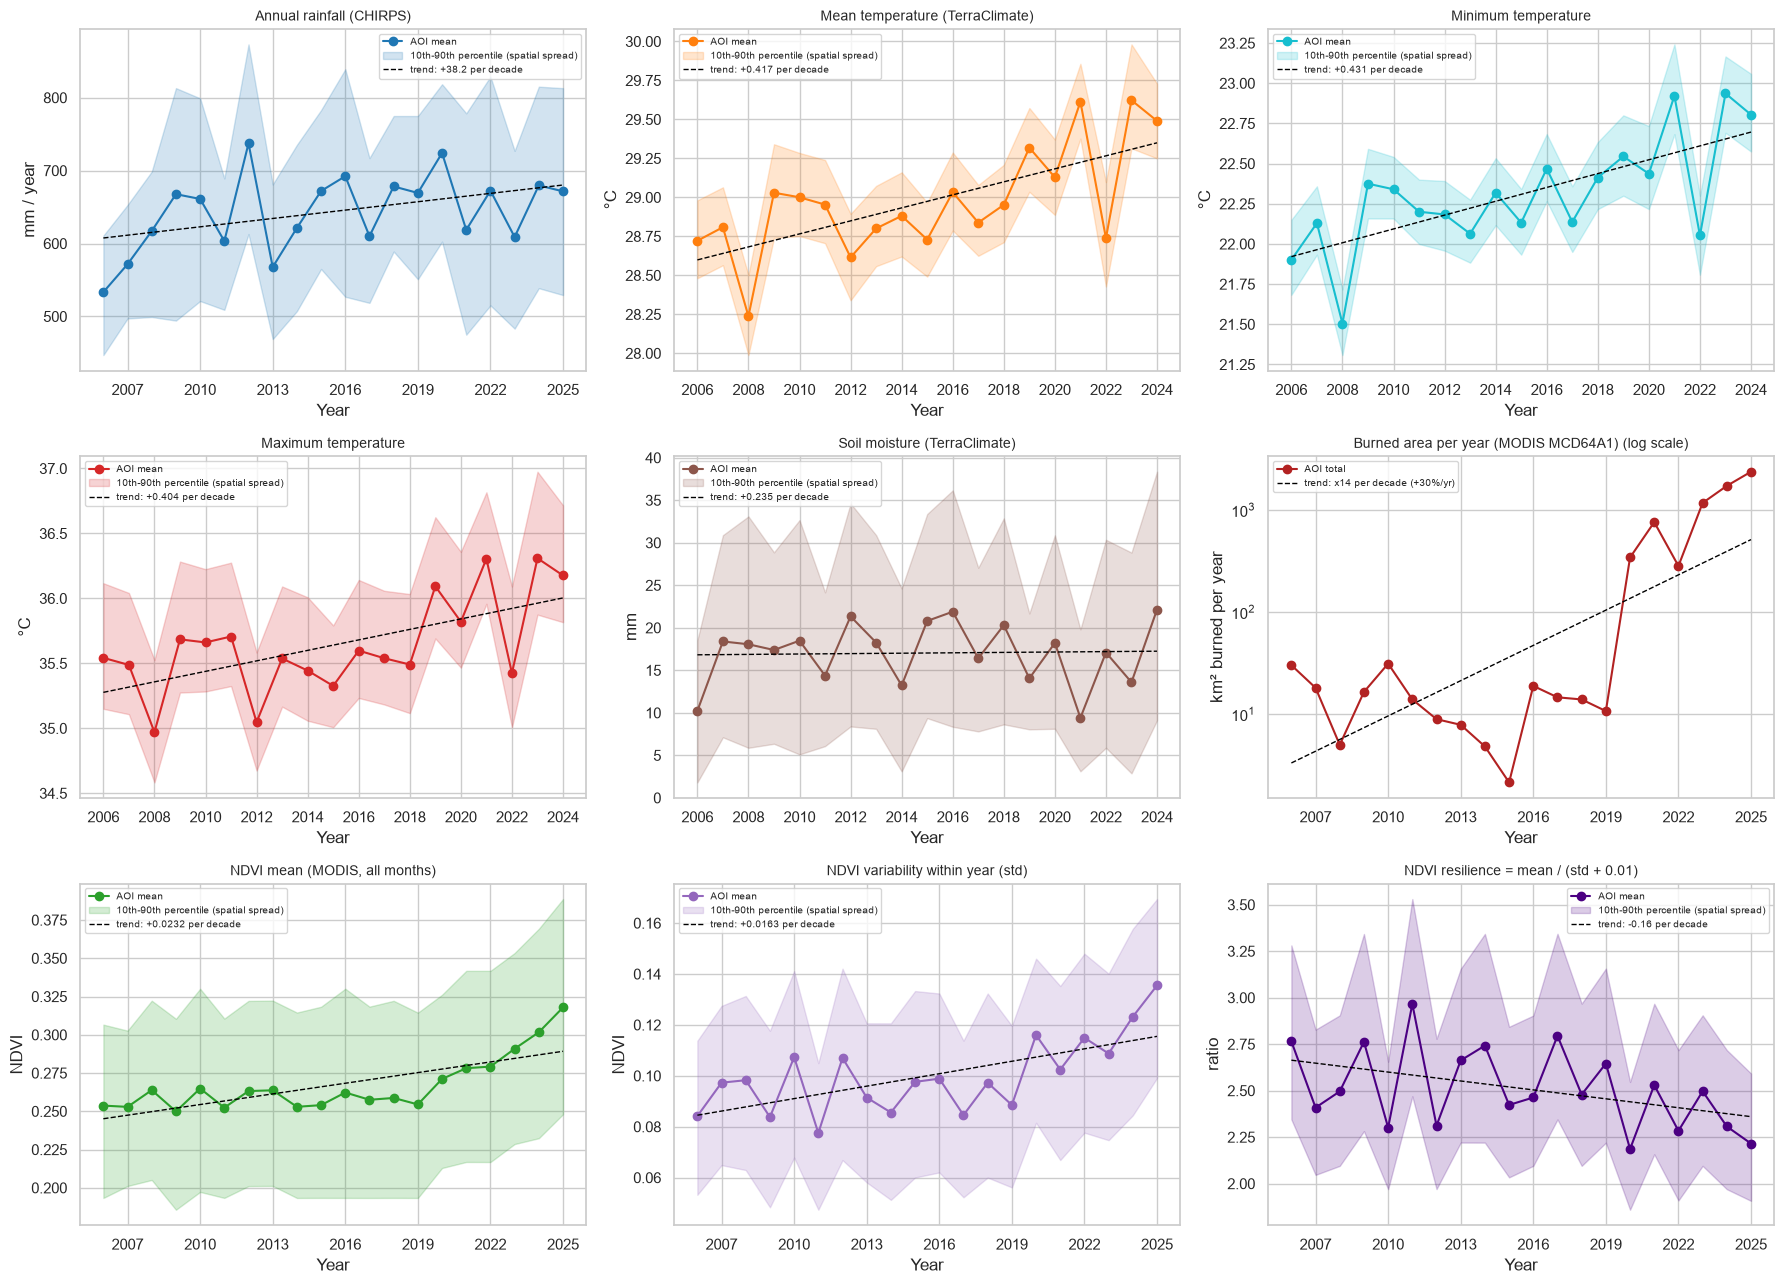

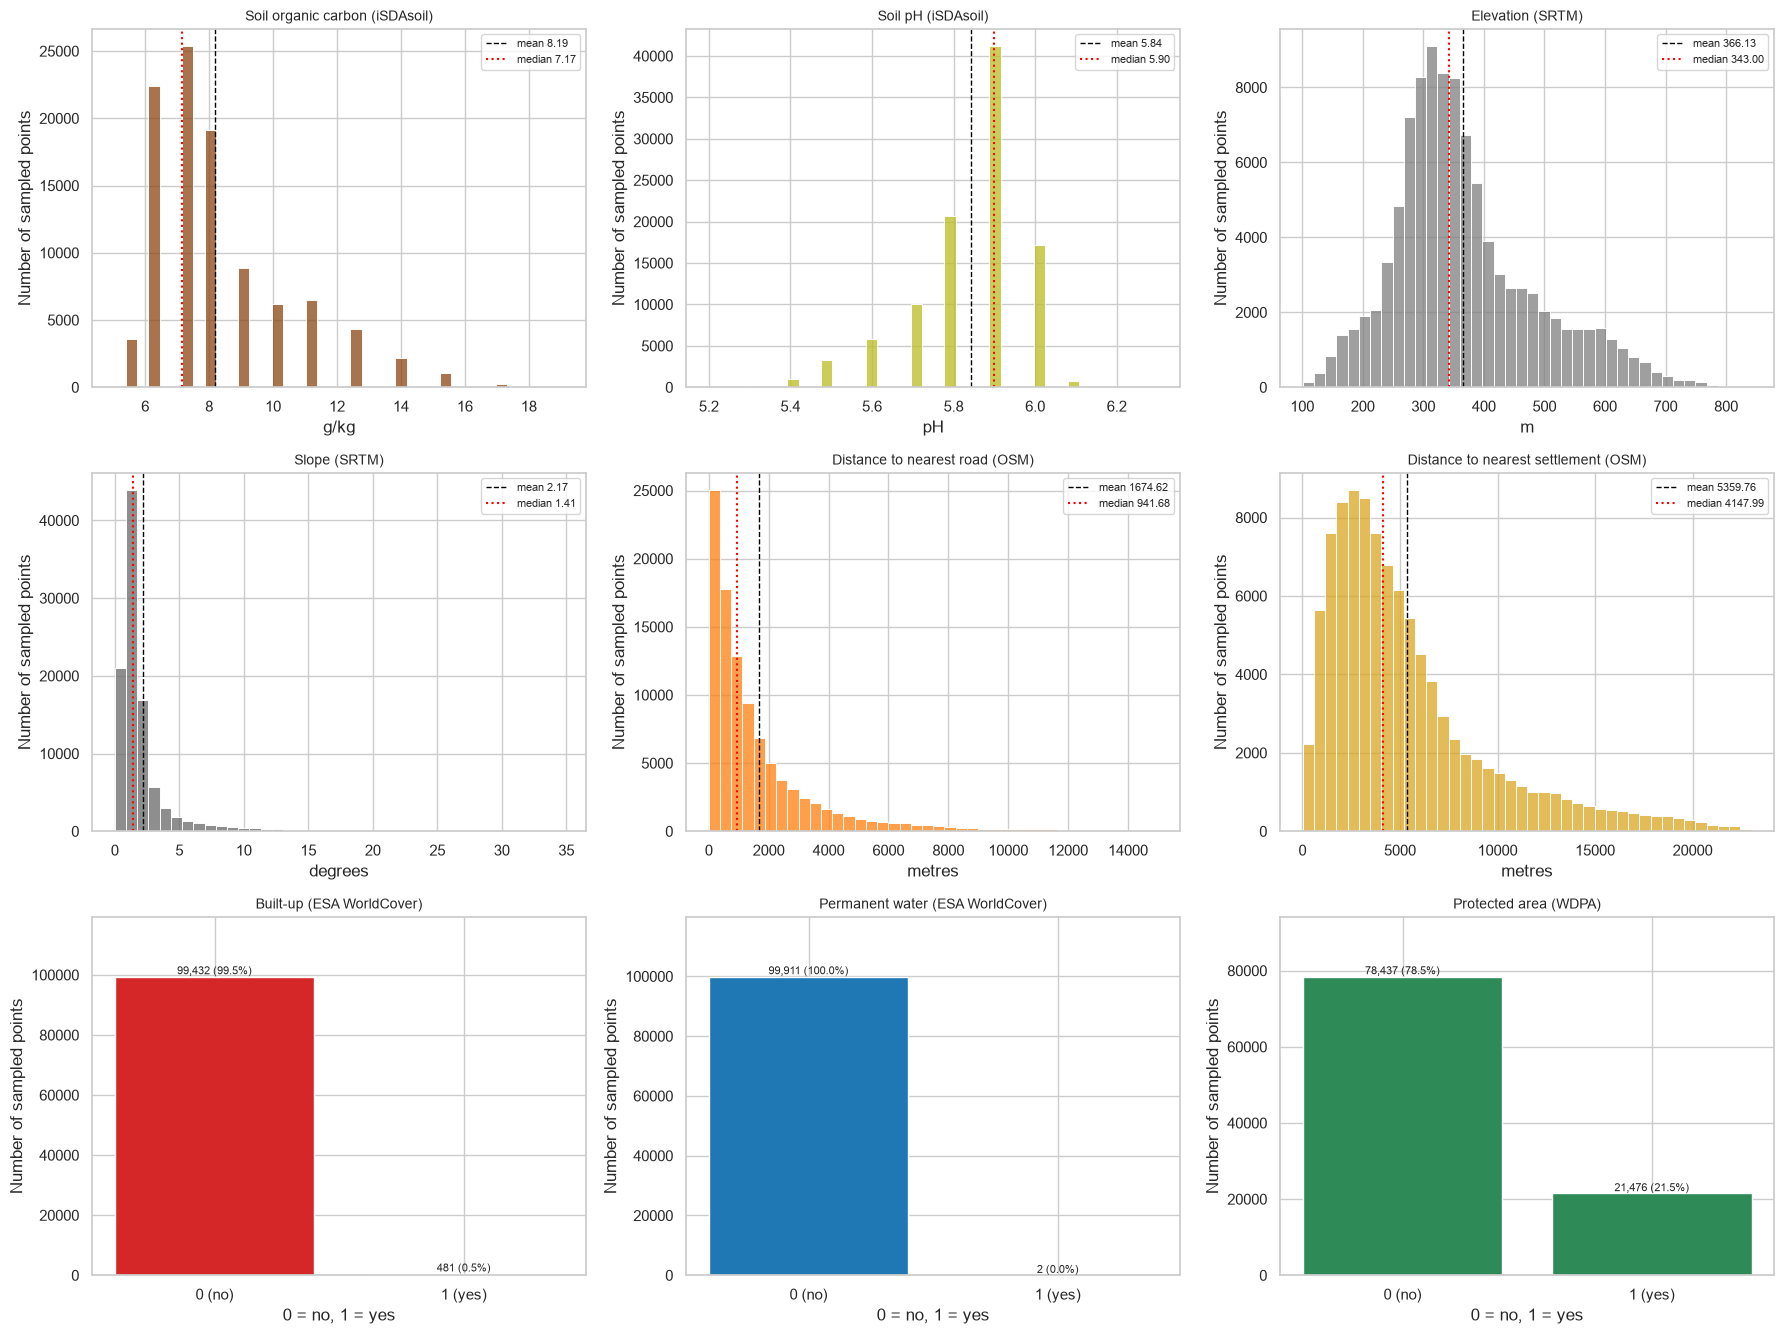

STATIC FEATURES (sampled points)
            soc        ph  elevation     slope  dist_to_road_m  \
count  99913.00  99913.00   99913.00  99913.00        99913.00   
mean       8.19      5.84     366.13      2.17         1674.62   
std        2.08      0.13     117.47      2.77         2103.37   
min        5.05      5.20     101.00      0.00            0.01   
25%        6.39      5.80     290.00      0.95          373.38   
50%        7.17      5.90     343.00      1.41          941.68   
75%        8.97      5.90     423.00      2.11         2083.01   
max       19.09      6.30     842.00     34.79        14987.53   

       dist_to_settlement_m  built_up    water  protected  
count              99913.00  99913.00  99913.0   99913.00  
mean                5359.76      0.00      0.0       0.21  
std                 4235.03      0.07      0.0       0.41  
min                   17.99      0.00      0.0       0.00  
25%                 2396.49      0.00      0.0       0.00  
50%         

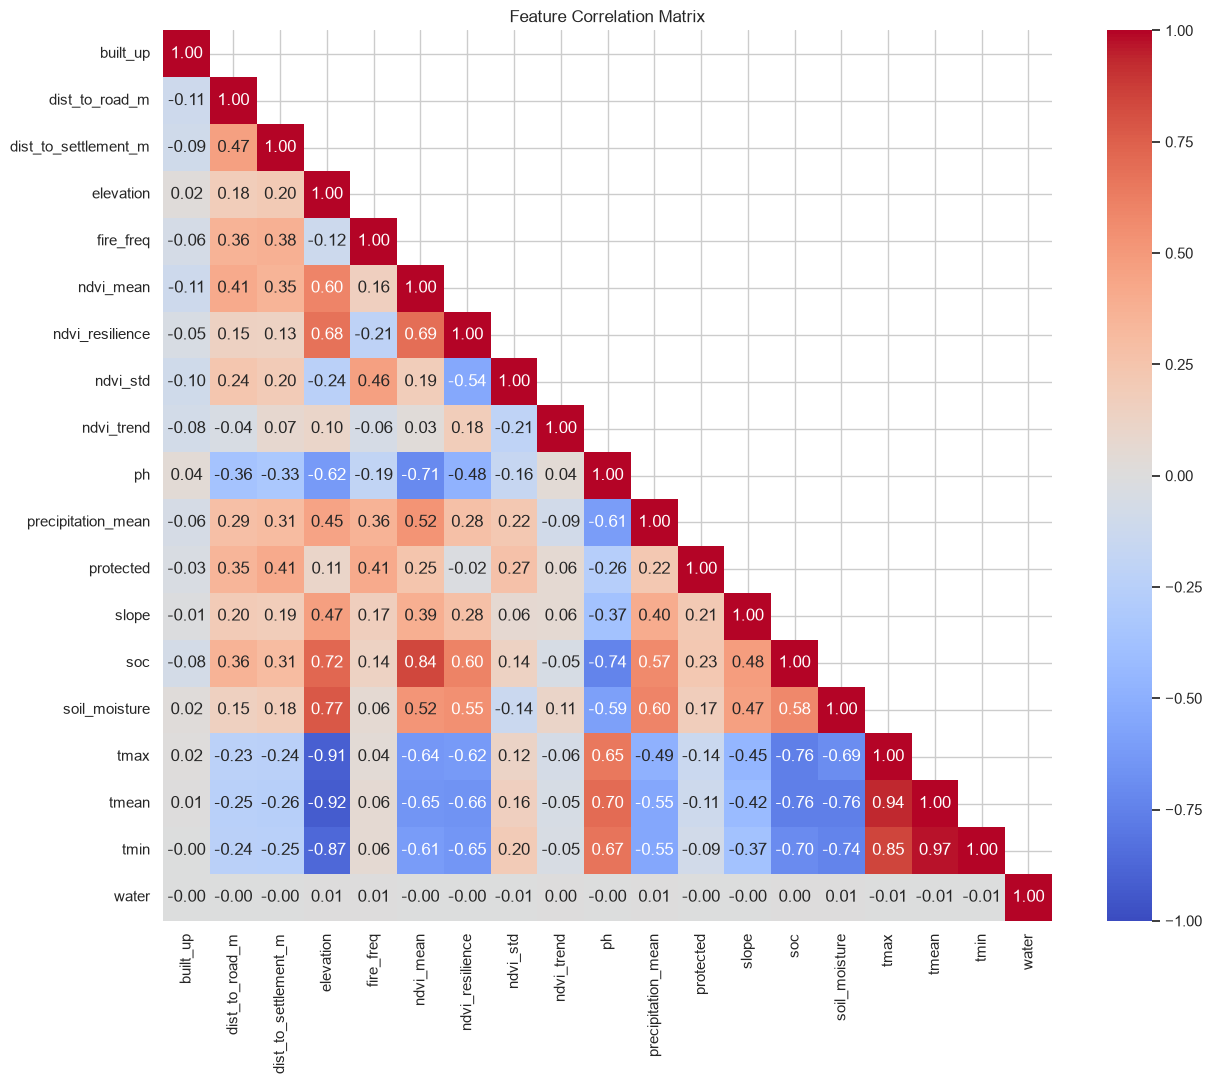


Pairs with |rho| >= 0.8:
feature_1 feature_2   rho
     tmin     tmean  0.97
    tmean      tmax  0.94
    tmean elevation -0.92
     tmax elevation -0.91
     tmin elevation -0.87
     tmin      tmax  0.85
      soc ndvi_mean  0.84


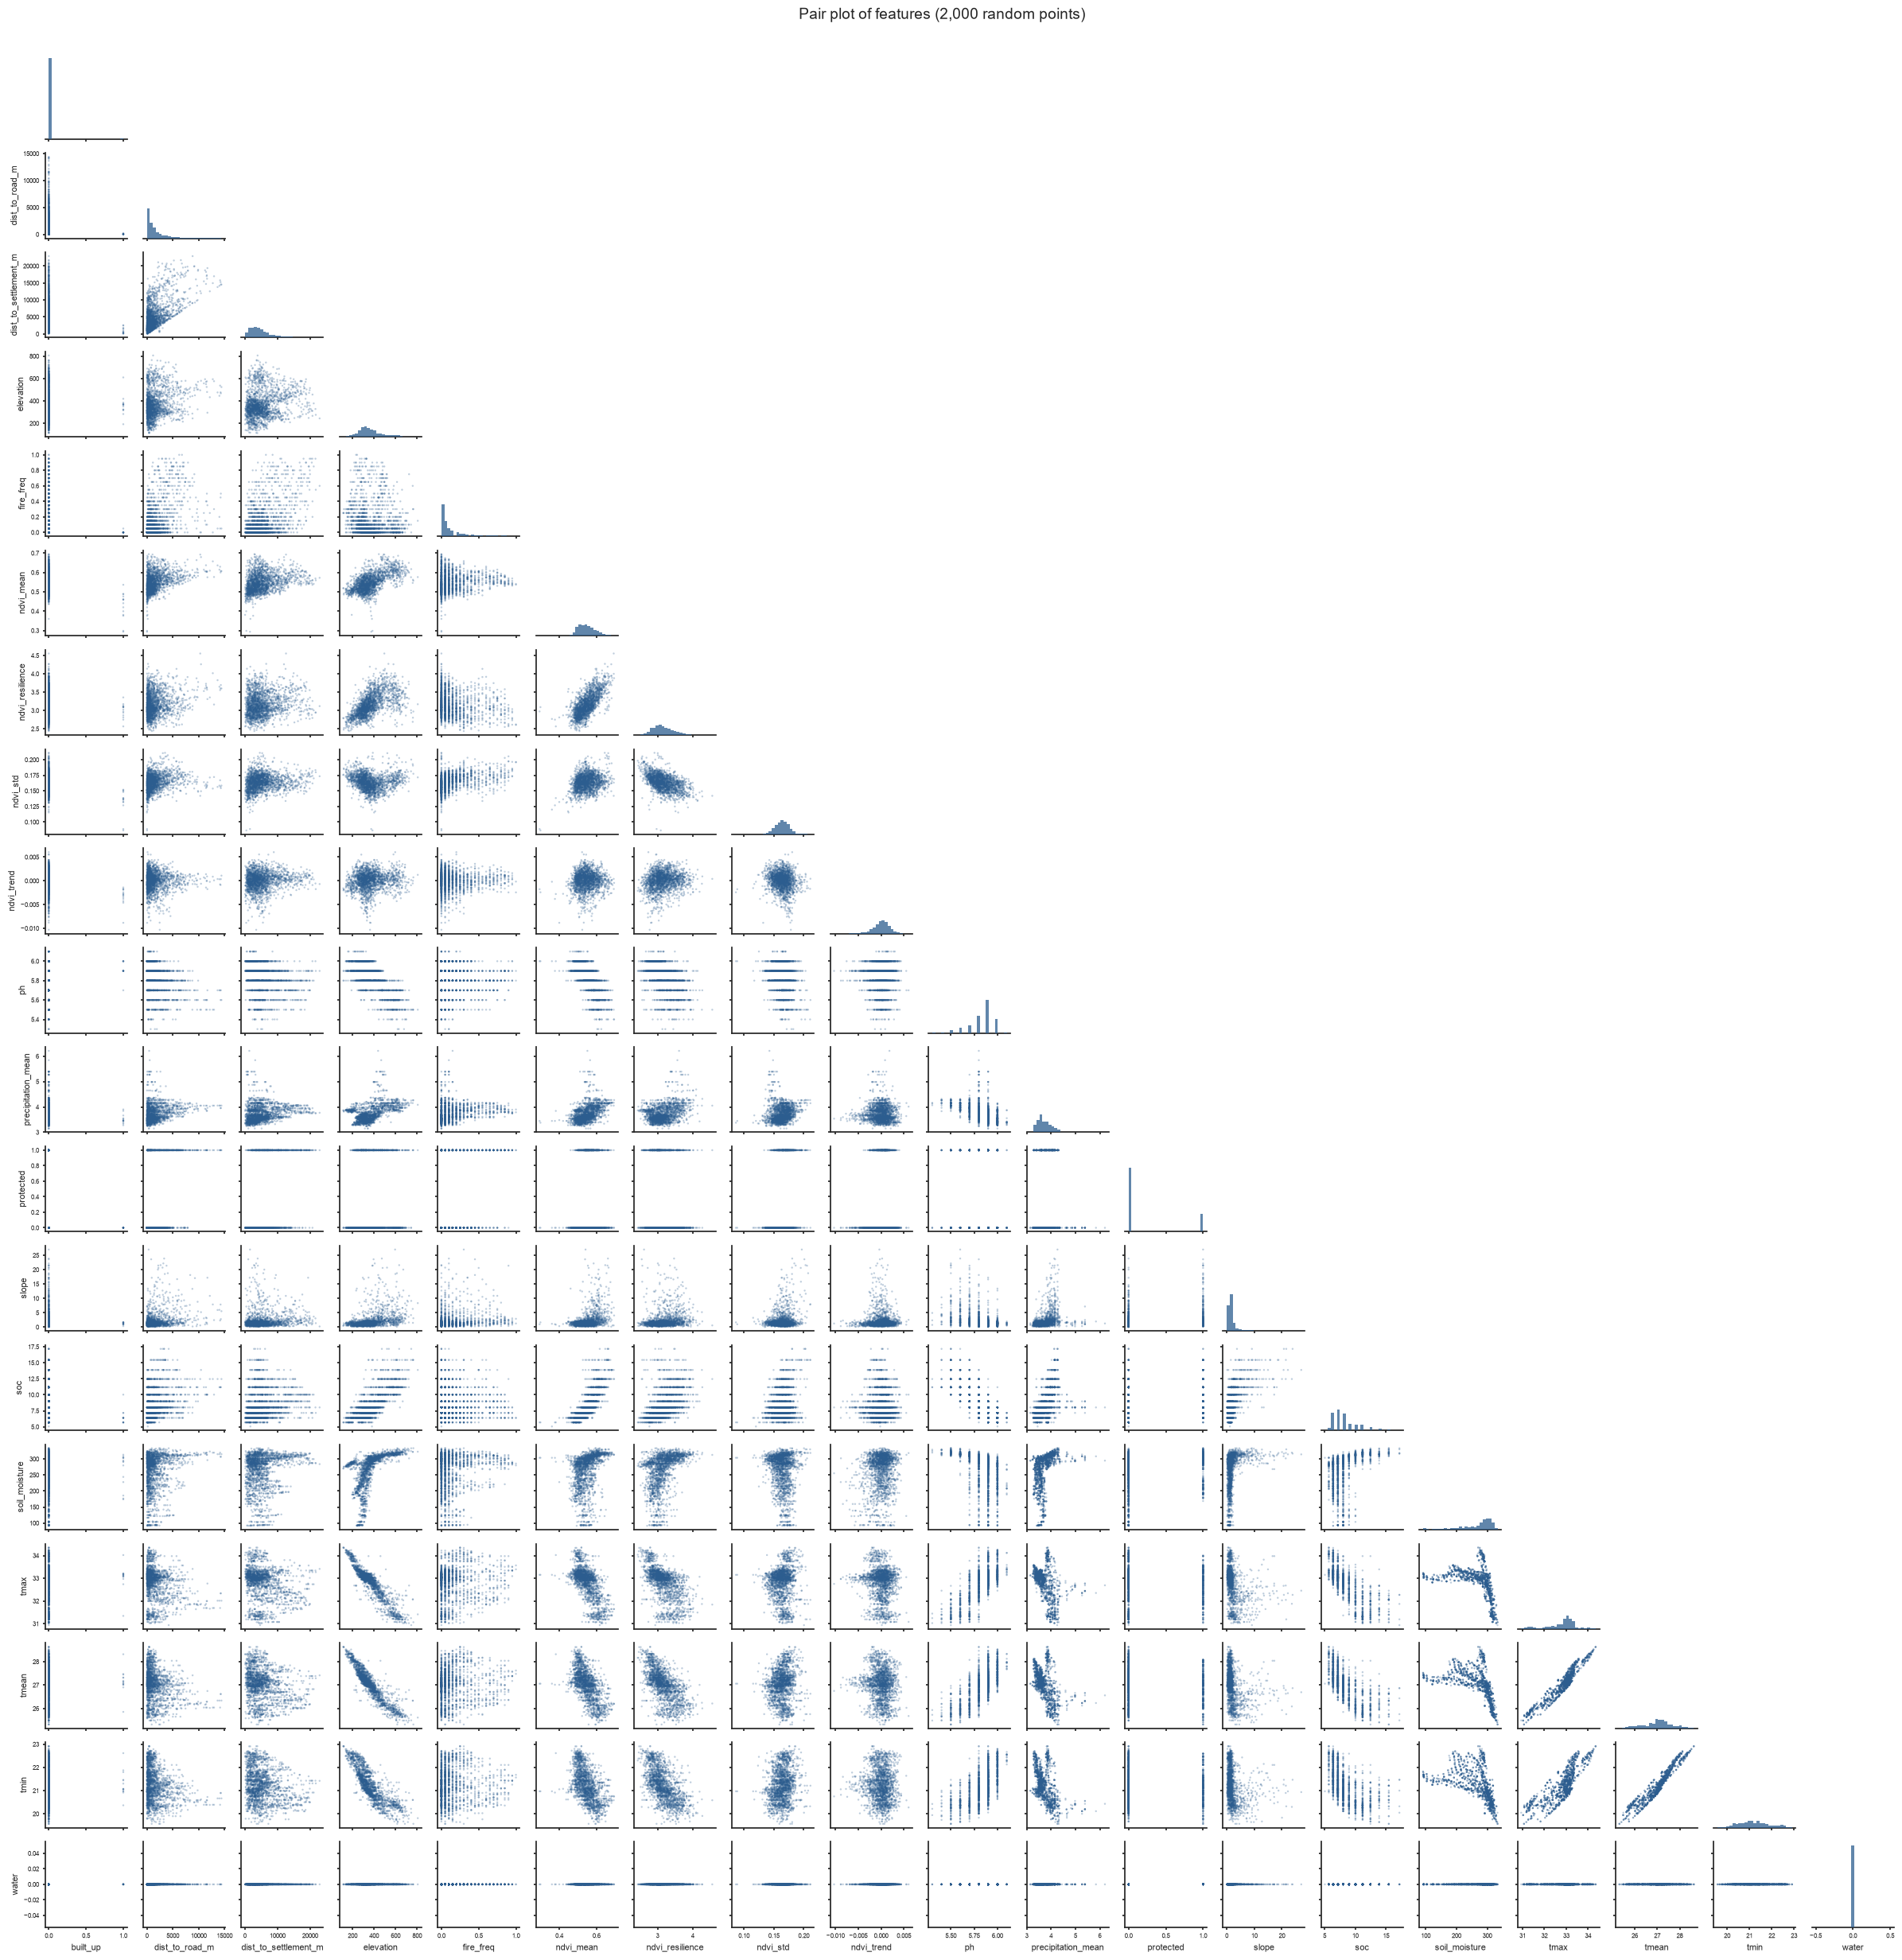

Week 1 EDA Report complete. Figures saved to 'reports/figures/'


In [10]:
from matplotlib.ticker import MaxNLocator

SCALE_TS = 1000   # metres, for the yearly series
REDUCER = ee.Reducer.mean().combine(ee.Reducer.percentile([10, 90]), sharedInputs=True)
EMPTY = ee.Image.constant(0).updateMask(ee.Image.constant(0))   # fully masked image
YEARS = range(min(CLIMATE_YEARS[0], NDVI_YEARS[0], FIRE_LONG_YEARS[0]),
              max(CLIMATE_YEARS[1], NDVI_YEARS[1], FIRE_LONG_YEARS[1]) + 1)


def year_col(col_id, band, y):
    start = ee.Date.fromYMD(y, 1, 1)
    return ee.ImageCollection(col_id).select(band).filterDate(start, start.advance(1, "year"))


def guarded(col, build, names):
    """Build an image from a collection, or a masked placeholder if the collection is empty."""
    empty = ee.Image.cat([EMPTY.rename(n) for n in names])
    return ee.Image(ee.Algorithms.If(col.size().gt(0), build(col), empty))


def year_stack(y):
    """All time-varying features for one full calendar year."""
    precip = guarded(year_col("UCSB-CHG/CHIRPS/DAILY", "precipitation", y),
                     lambda c: c.sum().rename("precipitation"), ["precipitation"])

    def build_tc(c):
        m = c.mean()
        tmin = m.select("tmmn").multiply(0.1)          # TerraClimate scale 0.1
        tmax = m.select("tmmx").multiply(0.1)
        return ee.Image.cat([
            tmin.rename("tmin"), tmax.rename("tmax"),
            tmin.add(tmax).divide(2).rename("tmean"),
            m.select("soil").multiply(0.1).rename("soil_moisture"),
        ])
    tc = guarded(year_col("IDAHO_EPSCOR/TERRACLIMATE", ["tmmn", "tmmx", "soil"], y),
                 build_tc, ["tmin", "tmax", "tmean", "soil_moisture"])

    burn = guarded(year_col("MODIS/061/MCD64A1", "BurnDate", y),
                   lambda c: c.max().gt(0).unmask(0).rename("fire_freq"), ["fire_freq"])

    def build_ndvi(c):
        c = c.map(lambda i: i.multiply(0.0001))
        r = c.reduce(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True))
        m = r.select("NDVI_mean").rename("ndvi_mean")
        s = r.select("NDVI_stdDev").rename("ndvi_std")
        return ee.Image.cat([m, s, m.divide(s.add(0.01)).rename("ndvi_resilience")])
    ndvi = guarded(year_col("MODIS/061/MOD13Q1", "NDVI", y),
                   build_ndvi, ["ndvi_mean", "ndvi_std", "ndvi_resilience"])

    return ee.Image.cat([precip, tc, burn, ndvi])


# ======================= PART 1: yearly series (cached, resumable) =======================
cache = DATA_PROCESSED / "timeseries_all_features.csv"
done = pd.read_csv(cache) if cache.exists() else pd.DataFrame(columns=["year"])
rows = done.to_dict("records")
have = set(done["year"].astype(int))

for y in YEARS:
    if y in have:
        continue
    print(f"Fetching {y} ...")
    stats = year_stack(y).reduceRegion(reducer=REDUCER, geometry=aoi_ee, scale=SCALE_TS,
                                       maxPixels=1e9, tileScale=4, bestEffort=True).getInfo()
    rows.append({"year": y, **stats})
    pd.DataFrame(rows).sort_values("year").to_csv(cache, index=False)   # save after every year

ts = pd.DataFrame(rows).sort_values("year").reset_index(drop=True)

# ---- burned area instead of fraction (converted locally from the cached fraction) ----
BURNED_UNIT = "km2"      # "km2" -> burned area in km2 | "pct" -> % of the AOI
AOI_KM2 = aoi_gdf.to_crs(aoi_gdf.estimate_utm_crs()).area.sum() / 1e6 
if BURNED_UNIT == "km2":
    ts["burned_area_mean"] = ts["fire_freq_mean"] * AOI_KM2
    burned_label = "km² burned per year"
else:
    ts["burned_area_mean"] = ts["fire_freq_mean"] * 100
    burned_label = "% of AOI burned per year"
print(f"AOI area: {AOI_KM2:,.0f} km²")

# (column, title, y-label, colour, show spatial-spread band)
ANNUAL_PANELS = [
    ("precipitation",   "Annual rainfall (CHIRPS)",              "mm / year",    "tab:blue",   True),
    ("tmean",           "Mean temperature (TerraClimate)",       "°C",           "tab:orange", True),
    ("tmin",            "Minimum temperature",                   "°C",           "tab:cyan",   True),
    ("tmax",            "Maximum temperature",                   "°C",           "tab:red",    True),
    ("soil_moisture",   "Soil moisture (TerraClimate)",          "mm",           "tab:brown",  True),
    ("burned_area",     "Burned area per year (MODIS MCD64A1)",  burned_label,   "firebrick",  False),
    ("ndvi_mean",       "NDVI mean (MODIS, all months)",         "NDVI",         "tab:green",  True),
    ("ndvi_std",        "NDVI variability within year (std)",    "NDVI",         "tab:purple", True),
    ("ndvi_resilience", "NDVI resilience = mean / (std + 0.01)", "ratio",        "indigo",     True),
]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for ax, (col, title, ylabel, color, band) in zip(axes.ravel(), ANNUAL_PANELS):
    ok = ts.dropna(subset=[f"{col}_mean"])
    if col == "burned_area":
        # values span ~2 to ~2,400 km2 -> log scale so the small 2006-2019 years stay visible
        ax.plot(ok["year"], ok[f"{col}_mean"], marker="o", color=color, label="AOI total")
        ax.set_yscale("log")
        pos = ok[ok[f"{col}_mean"] > 0]
        if len(pos) >= 3:
            # exponential trend = straight line on the log axis
            s, b = np.polyfit(pos["year"], np.log10(pos[f"{col}_mean"]), 1)
            ax.plot(pos["year"], 10 ** (s * pos["year"] + b), "--", color="black", lw=1,
                    label=f"trend: x{10 ** (s * 10):,.0f} per decade ({(10 ** s - 1) * 100:+.0f}%/yr)")
        ax.set_title(title + " (log scale)", fontsize=10)
        ax.set_xlabel("Year")
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend(fontsize=7)
        continue
    ax.plot(ok["year"], ok[f"{col}_mean"], marker="o", color=color,
            label="AOI mean" if band else "AOI total")
    if band:
        ax.fill_between(ok["year"], ok[f"{col}_p10"], ok[f"{col}_p90"], color=color, alpha=0.2,
                        label="10th-90th percentile (spatial spread)")
    if len(ok) >= 3:
        s, b = np.polyfit(ok["year"], ok[f"{col}_mean"], 1)
        ax.plot(ok["year"], s * ok["year"] + b, "--", color="black", lw=1,
                label=f"trend: {s * 10:+.3g} per decade")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(fontsize=7)
                


plt.tight_layout()
plt.savefig(FIGURES / "01a_time_varying_features_by_year.png", dpi=300)
plt.show()

# ======================= PART 2: static features (real values of the sampled points) =======================
src = gdf

# (column, title, x-label, colour)
STATIC_PANELS = [
    ("soc",            "Soil organic carbon (iSDAsoil)",  "g/kg",    "saddlebrown"),
    ("ph",             "Soil pH (iSDAsoil)",              "pH",      "tab:olive"),
    ("elevation",      "Elevation (SRTM)",                "m",       "tab:gray"),
    ("slope",          "Slope (SRTM)",                    "degrees", "dimgray"),
    ("dist_to_road_m", "Distance to nearest road (OSM)",  "metres",  "tab:orange"),
    ("dist_to_settlement_m", "Distance to nearest settlement (OSM)", "metres", "goldenrod"),
    ("built_up",       "Built-up (ESA WorldCover)",       "0 = no, 1 = yes", "tab:red"),
    ("water",          "Permanent water (ESA WorldCover)", "0 = no, 1 = yes", "tab:blue"),
    ("protected",      "Protected area (WDPA)",           "0 = no, 1 = yes", "seagreen"),
]


n_rows = int(np.ceil(len(STATIC_PANELS) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4.5 * n_rows))
for ax, (col, title, xlabel, color) in zip(axes.ravel(), STATIC_PANELS):
    vals = src[col].dropna() if col in src.columns else pd.Series(dtype=float)
    if vals.empty:
        ax.text(0.5, 0.5, f"'{col}' missing or all NaN", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, fontsize=10)
        continue
    if set(vals.unique()) <= {0, 1}:                 # binary mask -> bar of counts with share of points
        counts = vals.astype(int).value_counts().reindex([0, 1], fill_value=0)
        bars = ax.bar(["0 (no)", "1 (yes)"], counts.values, color=color)
        ax.bar_label(bars, labels=[f"{n:,} ({n / len(vals):.1%})" for n in counts.values], fontsize=8)
        ax.set_ylim(0, counts.max() * 1.2)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Number of sampled points")
        ax.set_title(title, fontsize=10)
        continue
    sns.histplot(vals, bins=40, color=color, ax=ax)
    ax.axvline(vals.mean(), color="black", ls="--", lw=1, label=f"mean {vals.mean():.2f}")
    ax.axvline(vals.median(), color="red", ls=":", lw=1.5, label=f"median {vals.median():.2f}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of sampled points")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(STATIC_PANELS):]:     # hide the unused panel
    ax.set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES / "01b_static_feature_distributions.png", dpi=300)
plt.show()

# ======================= PART 3: summary tables of the real values =======================
START, END = 2006, 2025

static_cols = [c for c, *_ in STATIC_PANELS if c in src.columns]
print("STATIC FEATURES (sampled points)")
print(src[static_cols].describe().round(2))

ts_period = ts[(ts["year"] >= START) & (ts["year"] <= END)]
annual_cols = [f"{c}_mean" for c, *_ in ANNUAL_PANELS if f"{c}_mean" in ts_period.columns]
yearly = ts_period[annual_cols].rename(columns=lambda c: c.replace("_mean", ""))
print(f"\nYEARLY FEATURES (AOI mean per year, {START}-{END}; burned_area in {burned_label.split(' per')[0]})")
print(yearly.describe().round(2))

mean_table = pd.DataFrame({f"mean_{START}_{END}": yearly.mean().round(3), "n_years": yearly.count()})
print(f"\nMEAN OF THE WHOLE {START}-{END} SERIES")
print(mean_table)

static_means = src[static_cols].mean().round(3).rename("value")
combined = pd.concat([
    mean_table[f"mean_{START}_{END}"].rename("value").to_frame().assign(type=f"yearly mean {START}-{END}"),
    static_means.to_frame().assign(type="static (sampled points)"),
])
combined.to_csv(DATA_PROCESSED / "feature_means_summary.csv")
print(f"\nSaved: {DATA_PROCESSED / 'feature_means_summary.csv'}")

# ======================= PART 4: correlation matrix + pair plot =======================
# Not included: dummy, aspect, proxy_target. ndvi_trend is the outcome behind the label (section 4):
# it is shown here to see how it relates to the conditions, but it is never used as a predictor.
FEATURES = ["built_up", "dist_to_road_m", "dist_to_settlement_m", "elevation", "fire_freq",
            "ndvi_mean", "ndvi_resilience", "ndvi_std", "ndvi_trend", "ph", "precipitation_mean",
            "protected", "slope", "soc", "soil_moisture", "tmax", "tmean", "tmin", "water"]   # alphabetical
SHOW_DIAGONAL = True      # True: diagonal shows 1.00 | False: hidden, exactly like your reference image
PAIR_SAMPLE = 2000        # points used in the pair plot

df = gdf[[c for c in FEATURES if c in gdf.columns]].copy()
not_in_df = [c for c in FEATURES if c not in gdf.columns]
all_nan = [c for c in df.columns if df[c].isna().all()]
constant = [c for c in df.columns if c not in all_nan and df[c].nunique(dropna=True) <= 1]
df = df.drop(columns=all_nan + constant)

print(f"\nFeatures used for correlation/pair plot: {df.shape[1]} of {len(FEATURES)}")
if not_in_df: print("  not in dataframe  :", not_in_df)
if all_nan:   print("  all NaN (dropped) :", all_nan)
if constant:  print("  constant (dropped):", constant)

# ---- correlation matrix ----
corr = df.corr(method="spearman")                         # NaNs handled pairwise, robust to skew
m = len(corr)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1 if SHOW_DIAGONAL else 0)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(FIGURES / "02_correlation_matrix.png", dpi=300)
plt.show()

pairs = corr.where(np.tril(np.ones((m, m), dtype=bool), k=-1)).stack().rename("rho").reset_index()
pairs.columns = ["feature_1", "feature_2", "rho"]
strong = pairs[pairs["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False)
print("\nPairs with |rho| >= 0.8:")
print(strong.round(2).to_string(index=False) if not strong.empty else "none")

# ---- pair plot ----
sample = df.sample(min(PAIR_SAMPLE, len(df)), random_state=RANDOM_STATE)
sns.set_theme(style="ticks")
g = sns.pairplot(
    sample, corner=True, diag_kind="hist", height=1.3,
    plot_kws=dict(s=3, alpha=0.3, edgecolor="none", rasterized=True, color="#2c5d8f"),
    diag_kws=dict(bins=25, edgecolor="none", color="#2c5d8f"),
)
for a in g.axes.flatten():
    if a is not None:
        a.tick_params(labelsize=6, length=2)
        a.xaxis.label.set_size(8)
        a.yaxis.label.set_size(8)
g.figure.suptitle(f"Pair plot of features ({len(sample):,} random points)", y=1.01, fontsize=14)
g.savefig(FIGURES / "02b_pairplot_features.png", dpi=200, bbox_inches="tight")
plt.show()

print("Week 1 EDA Report complete. Figures saved to 'reports/figures/'")

In [11]:
gdf = gdf.drop(columns=["dummy", "proxy_target"], errors="ignore")
print(gdf.columns.tolist())

['geometry', 'built_up', 'elevation', 'fire_freq', 'ndvi_mean', 'ndvi_resilience', 'ndvi_std', 'ndvi_trend', 'ph', 'precipitation_mean', 'protected', 'slope', 'soc', 'soil_moisture', 'tmax', 'tmean', 'tmin', 'water', 'dist_to_road_m', 'dist_to_settlement_m']


In [12]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 99913 entries, 0 to 99912
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   geometry              99913 non-null  geometry
 1   built_up              99913 non-null  int64   
 2   elevation             99913 non-null  int64   
 3   fire_freq             99913 non-null  float64 
 4   ndvi_mean             99913 non-null  float64 
 5   ndvi_resilience       99913 non-null  float64 
 6   ndvi_std              99913 non-null  float64 
 7   ndvi_trend            99913 non-null  float64 
 8   ph                    99913 non-null  float64 
 9   precipitation_mean    99913 non-null  float64 
 10  protected             99913 non-null  int64   
 11  slope                 99913 non-null  float64 
 12  soc                   99913 non-null  float64 
 13  soil_moisture         99913 non-null  float64 
 14  tmax                  99913 non-null  float64 

# Modelling

In [13]:
import re
import time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import ee
import geemap
import torch
import torch.nn as nn
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RandomizedSearchCV, ParameterSampler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, f1_score, accuracy_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from IPython.display import display
from sklearn.base import clone
from sklearn.utils import estimator_html_repr
from sklearn import set_config

In [14]:
# ============================ SETTINGS ============================
LABEL_COL = "ndvi_trend"          # outcome that defines the label (NDVI change per year, 2006-2025)
HIGH_Q, LOW_Q = 0.70, 0.30        # top 30% = high potential (1), bottom 30% = low potential (0)
BLOCK_M = 10_000                  # spatial block size in metres
TEST_SIZE = 0.30                  # share of blocks held out for the final test
N_ITER = 20                       # random-search iterations per tabular model (lower it to run faster)
N_ITER_PATCH = 6                  # random-search configurations for the patch CNN (each is trained 5 times)
CANDIDATES = ["precipitation_mean", "soil_moisture", "tmean", "soc", "ph",
              "elevation", "slope", "dist_to_road_m", 'built_up', 'ndvi_mean', 
              'ndvi_resilience', 'ndvi_std', 'tmax', 'protected',
              'tmin', 'water', 'dist_to_settlement_m']
# Not predictors: ndvi_trend (defines the label, so it would leak the answer) and
# fire_freq (kept for the separate Risk Score)

# ---- spatial CNN: image patches around every point ----
PATCH_RADIUS = 2                  # 2 -> 5 x 5 pixels (1.25 km window at 250 m); 3 -> 7 x 7
# the CNN sees the SAME layers as the table models (every candidate except the point-based OSM distances,
# which go in as SCALAR_FEATURES next to the patch). Cell "1. DATA" drops any layer that is not a predictor.
PATCH_BANDS = ["precipitation_mean", "soil_moisture", "tmean", "tmin", "tmax",          # climate
               "soc", "ph", "elevation", "slope",                                       # soil + terrain
               "ndvi_mean", "ndvi_std", "ndvi_resilience",                              # vegetation (MODIS)
               "built_up", "water", "protected"]                                        # land cover + protection
COARSE_BANDS = {"precipitation_mean", "soil_moisture", "tmean", "tmin", "tmax"}   # 4-5 km sources: interpolate, do not aggregate
# layers without a native pixel grid (a painted vector layer, multi-year MODIS composites):
# computed straight on the 250 m grid, exactly as they were sampled for the table models
DIRECT_BANDS = {"protected", "ndvi_mean", "ndvi_std", "ndvi_resilience"}
SCALAR_FEATURES = [c for c in ["dist_to_road_m", "dist_to_settlement_m"] if c in CANDIDATES]   # local OSM feature, fed next to the patch
BATCH = 250                       # points per Earth Engine request (15 layers x 25 pixels per point; lower it if you get memory errors)
CNN_NAME = "CNN (2D patches)"
slug = lambda s: re.sub(r"\W+", "_", s.lower()).strip("_")

In [15]:
# ============================ 1. DATA ============================
data = gdf.drop(columns=["dummy", "proxy_target"], errors="ignore").copy()
assert data.index.is_unique, "gdf index must be unique (it is used as the point id for the patches)"

# Fill missing distances with the max observed distance (meaning "very far from a road")
data['dist_to_road_m'] = data['dist_to_road_m'].fillna(data['dist_to_road_m'].max())
data['dist_to_settlement_m'] = data['dist_to_settlement_m'].fillna(data['dist_to_settlement_m'].max())

utm = data.estimate_utm_crs()                                   # metric CRS for block sizes
xy_utm = data.to_crs(utm).geometry
data["x_m"], data["y_m"] = xy_utm.x.values, xy_utm.y.values
data["block"] = ((data["x_m"] // BLOCK_M).astype(int).astype(str) + "_" +
                 (data["y_m"] // BLOCK_M).astype(int).astype(str))

PREDICTORS = [c for c in CANDIDATES if c in data.columns and data[c].notna().mean() > 0.95]
SCALAR_FEATURES = [c for c in SCALAR_FEATURES if c in PREDICTORS]
PATCH_BANDS = [b for b in PATCH_BANDS if b in PREDICTORS]          # the CNN uses the same layers as the other models
print("Predictors used:", PREDICTORS)
print("Left out        :", [c for c in CANDIDATES if c not in PREDICTORS])
print(f"CNN patch layers ({len(PATCH_BANDS)}):", PATCH_BANDS, "| CNN scalar inputs:", SCALAR_FEATURES)


Predictors used: ['precipitation_mean', 'soil_moisture', 'tmean', 'soc', 'ph', 'elevation', 'slope', 'dist_to_road_m', 'built_up', 'ndvi_mean', 'ndvi_resilience', 'ndvi_std', 'tmax', 'protected', 'tmin', 'water', 'dist_to_settlement_m']
Left out        : []
CNN patch layers (15): ['precipitation_mean', 'soil_moisture', 'tmean', 'tmin', 'tmax', 'soc', 'ph', 'elevation', 'slope', 'ndvi_mean', 'ndvi_std', 'ndvi_resilience', 'built_up', 'water', 'protected'] | CNN scalar inputs: ['dist_to_road_m', 'dist_to_settlement_m']


In [16]:
# ============================ 2. IMAGE PATCHES FROM EARTH ENGINE (cached, protected against stale caches) ============================
import hashlib
R, H, C = PATCH_RADIUS, 2 * PATCH_RADIUS + 1, len(PATCH_BANDS)
crs = utm.to_string()                                           # e.g. "EPSG:32630"

# The cache folder is named by a fingerprint of the points (ids + coordinates), the layers and the patch size.
# If ANY of them changes, a new folder is used, so old patches can never be matched to the wrong points.
fingerprint = hashlib.md5(
    np.column_stack([data.index.values, data.geometry.x.values.round(6), data.geometry.y.values.round(6)]).tobytes()
    + ("|".join(PATCH_BANDS) + f"|r{R}").encode()).hexdigest()[:10]
PATCH_DIR = DATA_PROCESSED / "patches" / fingerprint
PATCH_DIR.mkdir(parents=True, exist_ok=True)
print("patch cache folder:", PATCH_DIR.name)

src = features_image if "features_image" in globals() else get_features_image(aoi_gdf)

def on_grid(band):
    """One band on the common UTM 250 m grid:
    coarse climate layers are interpolated, protected areas and NDVI composites are computed directly on the grid,
    fine layers are averaged (10 m WorldCover -> share of built-up / water in the 250 m cell)."""
    b = src.select(band)
    if band in COARSE_BANDS:
        return b.resample("bilinear").reproject(crs=crs, scale=TARGET_SCALE)
    if band in DIRECT_BANDS:
        return b.reproject(crs=crs, scale=TARGET_SCALE)
    # maxPixels 1024: a 250 m cell holds 625 WorldCover pixels (10 m), more than the old limit of 256
    return b.reduceResolution(ee.Reducer.mean(), maxPixels=1024).reproject(crs=crs, scale=TARGET_SCALE)

# every output band is named "<band>_<x>_<y>" with offsets from -R to +R pixels around the point
patch_img = ee.Image.cat([on_grid(b) for b in PATCH_BANDS]).neighborhoodToBands(ee.Kernel.square(R, "pixels"))

band_idx = {b: i for i, b in enumerate(PATCH_BANDS)}
name_rx = re.compile(r"^(.*)_(-?\d+)_(-?\d+)$")

def fetch_batch(batch):
    fc = geemap.gdf_to_ee(batch[["pid", "geometry"]])
    for attempt in range(3):
        try:
            return patch_img.sampleRegions(collection=fc, properties=["pid"], scale=TARGET_SCALE,
                                           tileScale=4, geometries=False).getInfo()["features"]
        except Exception as e:
            print(f"   attempt {attempt + 1}/3 failed: {str(e)[:150]}")
            time.sleep(10 * (attempt + 1))
    raise RuntimeError("Earth Engine batch failed three times")

def parse_batch(features):
    pids, arrs = [], []
    for f in features:
        p = f["properties"]
        a = np.full((C, H, H), np.nan, dtype=np.float32)
        for k, v in p.items():
            mt = name_rx.match(k)
            if mt and mt.group(1) in band_idx and v is not None:
                a[band_idx[mt.group(1)], int(mt.group(3)) + R, int(mt.group(2)) + R] = v   # [channel, row(y), col(x)]
        pids.append(int(p["pid"])); arrs.append(a)
    if not arrs:
        return np.array([], dtype=int), np.zeros((0, C, H, H), dtype=np.float32)
    return np.array(pids), np.stack(arrs)

# ---- alignment check: does the centre pixel of each patch match the value in the table for the same point? ----
CHECK_BANDS = [b for b in ["elevation", "precipitation_mean", "tmean", "soil_moisture"]
               if b in band_idx and b in data.columns]          # layers that must agree almost perfectly
MIN_R = 0.8

def alignment_report(pids, arr, label):
    pos_ = data.index.get_indexer(pids)
    out = {}
    for b, j in band_idx.items():
        if b in data.columns:
            tab, pc = data[b].iloc[pos_].to_numpy(), arr[:, j, R, R]
            ok_ = np.isfinite(tab) & np.isfinite(pc)
            out[b] = np.corrcoef(pc[ok_], tab[ok_])[0, 1] if ok_.sum() > 3 else np.nan
    print(f"{label}: " + " | ".join(f"{b} r={v:.2f}" for b, v in out.items()))
    return out

def assert_aligned(report, where):
    bad = {b: round(float(report[b]), 2) for b in CHECK_BANDS if not report[b] > MIN_R}
    assert not bad, (f"{where}: the patches do not match the table for the same points {bad} (need r > {MIN_R}). "
                     f"Delete {DATA_PROCESSED / 'patches'} and run again; if it still fails, the Earth Engine export is wrong.")

pid_df = data[["geometry"]].copy()
pid_df["pid"] = data.index.astype(int)


# ---- the download (cached per batch, resumable) ----
n_batches = int(np.ceil(len(pid_df) / BATCH))
print(f"\nFetching {H}x{H} patches of {C} layers for {len(pid_df)} points in {n_batches} batches (cached, resumable)")
for i in range(n_batches):
    fpath = PATCH_DIR / f"r{R}_batch_{i:04d}.npz"
    if fpath.exists():
        continue
    t0 = time.perf_counter()
    pid_b, arr_b = parse_batch(fetch_batch(pid_df.iloc[i * BATCH:(i + 1) * BATCH]))
    np.savez_compressed(fpath, pid=pid_b, patch=arr_b)
    print(f"  batch {i + 1}/{n_batches}: {len(pid_b)} patches in {time.perf_counter() - t0:.0f}s")

loaded = [np.load(f) for f in sorted(PATCH_DIR.glob(f"r{R}_batch_*.npz"))]
pid_all = np.concatenate([z["pid"] for z in loaded])
P_raw = np.concatenate([z["patch"] for z in loaded])
pos = pd.Series(np.arange(len(pid_all)), index=pid_all).reindex(data.index.astype(int))
P_all = np.full((len(data), C, H, H), np.nan, dtype=np.float32)       # aligned with the rows of `data`
have = pos.notna().values
P_all[have] = P_raw[pos[have].astype(int).values]
print(f"Patches received for {have.sum()} of {len(data)} points")


# fill gaps (points near the edge of the data): patch-channel mean first, then the global channel mean
n_gap = int(np.isnan(P_all).any(axis=(1, 2, 3)).sum())
P_all = np.where(np.isnan(P_all), np.nanmean(P_all, axis=(2, 3), keepdims=True), P_all)
P_all = np.where(np.isnan(P_all), np.nanmean(P_all, axis=(0, 2, 3), keepdims=True), P_all).astype(np.float32)
print(f"Patches with gaps that were filled: {n_gap} ({n_gap / len(data) * 100:.1f}%)")
np.save(PATCH_DIR / f"P_all_r{R}.npy", P_all)

patch cache folder: fab1dd2bf3

Fetching 5x5 patches of 15 layers for 99913 points in 400 batches (cached, resumable)
Patches received for 99913 of 99913 points
Patches with gaps that were filled: 0 (0.0%)


In [17]:
# ============================ 3. LABEL FROM THE OUTCOME ============================
d = data.dropna(subset=[LABEL_COL] + PREDICTORS).copy()
lo, hi = d[LABEL_COL].quantile([LOW_Q, HIGH_Q])
d = d[(d[LABEL_COL] <= lo) | (d[LABEL_COL] >= hi)].copy()       # drop the ambiguous middle
d["label"] = (d[LABEL_COL] >= hi).astype(int)
print(f"\n{LABEL_COL}: low <= {lo:.4f}, high >= {hi:.4f} (NDVI units per year)")
print("Labelled points:", len(d)); print(d["label"].value_counts().rename({0: "low (0)", 1: "high (1)"}))

X, y, groups = d[PREDICTORS], d["label"], d["block"].values
row_pos = data.index.get_indexer(d.index)                       # position of each labelled point in `data` / P_all
P = P_all[row_pos]                                              # (n, channels, H, W)
S = d[SCALAR_FEATURES].to_numpy(np.float32).reshape(len(d), -1)


ndvi_trend: low <= -0.0007, high >= 0.0009 (NDVI units per year)
Labelled points: 59948
label
low (0)     29974
high (1)    29974
Name: count, dtype: int64


In [18]:
# ============================ 4. SPATIAL TRAIN / TEST SPLIT (whole blocks held out) ============================
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
tr, te = next(gss.split(X, y, groups))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups[tr]
P_tr, P_te, S_tr, S_te = P[tr], P[te], S[tr], S[te]
y_tr_a, y_te_a = y_tr.to_numpy(), y_te.to_numpy()
print(f"\nTrain: {len(X_tr)} points in {len(set(g_tr))} blocks | Test: {len(X_te)} points in {len(set(groups[te]))} blocks")


Train: 42643 points in 114 blocks | Test: 17305 points in 49 blocks


In [19]:
# ============================ 5. THE 2D CNN ============================
class _Net(nn.Module):
    def __init__(self, c_in, n_scalar, filters, dropout):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(c_in, filters, 3, padding=1), nn.BatchNorm2d(filters), nn.ReLU(),
            nn.Conv2d(filters, filters * 2, 3, padding=1), nn.BatchNorm2d(filters * 2), nn.ReLU(),
            nn.AdaptiveAvgPool2d(2), nn.Flatten())                       # 2x2 summary, any patch size works
        self.head = nn.Sequential(nn.Linear(filters * 2 * 4 + n_scalar, 64), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, s):
        z = self.conv(x)
        if s.shape[1] > 0:
            z = torch.cat([z, s], dim=1)                                 # patch features + scalar inputs (e.g. road distance)
        return self.head(z).squeeze(1)


class PatchCNN:
    """2D CNN on (channels x H x W) patches + optional scalar features. Early stopping uses whole held-out BLOCKS."""

    def __init__(self, filters=32, dropout=0.3, lr=1e-3, weight_decay=1e-4, epochs=60,
                 batch_size=64, patience=8, augment=True, seed=0):
        self.filters, self.dropout, self.lr, self.weight_decay = filters, dropout, lr, weight_decay
        self.epochs, self.batch_size, self.patience, self.augment, self.seed = epochs, batch_size, patience, augment, seed

    def _prep(self, P, S):
        P = (P - self.mu_[None, :, None, None]) / self.sd_[None, :, None, None]
        S = (np.log1p(np.clip(S, 0, None)) - self.smu_) / self.ssd_       # distances are skewed -> log, then standardise
        return torch.tensor(P, dtype=torch.float32), torch.tensor(S, dtype=torch.float32)

    def fit(self, P, S, y, groups):
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        torch.manual_seed(self.seed)
        self.mu_, self.sd_ = P.mean(axis=(0, 2, 3)), P.std(axis=(0, 2, 3)) + 1e-6
        Sl = np.log1p(np.clip(S, 0, None))
        self.smu_, self.ssd_ = Sl.mean(axis=0), Sl.std(axis=0) + 1e-6

        ug = np.unique(groups); rng = np.random.RandomState(self.seed); rng.shuffle(ug)
        val_blocks = set(ug[:max(int(0.15 * len(ug)), 1)])                # 15% of the BLOCKS for early stopping
        is_val = np.array([g in val_blocks for g in groups])
        Xp, Xs = self._prep(P, S)
        yt = torch.tensor(y, dtype=torch.float32)
        tri, vai = np.where(~is_val)[0], np.where(is_val)[0]
        Xp_t, Xs_t, y_t = Xp[tri].to(dev), Xs[tri].to(dev), yt[tri].to(dev)
        Xp_v, Xs_v, y_v = Xp[vai].to(dev), Xs[vai].to(dev), yt[vai].to(dev)

        self.net_ = _Net(P.shape[1], S.shape[1], self.filters, self.dropout).to(dev)
        opt = torch.optim.AdamW(self.net_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        pos_w = torch.tensor([float((y[tri] == 0).sum() / max((y[tri] == 1).sum(), 1))], device=dev)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)

        best, best_state, wait = float("inf"), None, 0
        for _ in range(self.epochs):
            self.net_.train()
            order = torch.randperm(len(Xp_t), device=dev)
            for i in range(0, len(order), self.batch_size):
                idx = order[i:i + self.batch_size]
                if len(idx) < 2:                                          # BatchNorm needs at least 2 samples
                    continue
                xb = Xp_t[idx]
                if self.augment:                                          # random rotation / flip of the whole batch
                    xb = torch.rot90(xb, int(torch.randint(0, 4, (1,))), dims=(2, 3))
                    if torch.rand(1).item() < 0.5:
                        xb = torch.flip(xb, dims=(3,))
                opt.zero_grad()
                loss_fn(self.net_(xb, Xs_t[idx]), y_t[idx]).backward()
                opt.step()
            self.net_.eval()
            with torch.no_grad():
                v = loss_fn(self.net_(Xp_v, Xs_v), y_v).item()
            if v < best - 1e-4:
                best, wait = v, 0
                best_state = {k: t.detach().clone() for k, t in self.net_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.net_.load_state_dict(best_state)
        self.net_.cpu().eval()
        return self

    def predict_proba(self, P, S):
        Xp, Xs = self._prep(P, S)
        out = []
        with torch.no_grad():
            for i in range(0, len(Xp), 1024):
                out.append(torch.sigmoid(self.net_(Xp[i:i + 1024], Xs[i:i + 1024])).numpy())
        return np.concatenate(out)



In [20]:
# ============================ 5b. MAKE THE CNN A scikit-learn MODEL (so it can live in MODELS) ============================
class PatchStore:
    """Holds the image patches and block ids of ALL points; rows are looked up by the DataFrame index."""
    def __init__(self, patches, index, blocks):
        self.patches, self.index, self.blocks = patches, pd.Index(index), np.asarray(blocks)

    def get(self, idx):
        pos = self.index.get_indexer(idx)
        assert (pos >= 0).all(), "some rows have no patch"
        return self.patches[pos], self.blocks[pos]

    def __deepcopy__(self, memo):            # sklearn's clone() would otherwise copy every patch for every single fit
        return self


class PatchCNNClassifier(ClassifierMixin, BaseEstimator):
    """Takes the usual table X (index = point id). The patch of every row comes from the PatchStore,
    the scalar inputs (e.g. road distance) come from X[scalar_cols]. Early stopping uses whole blocks."""

    def __init__(self, store=None, scalar_cols=(), filters=32, dropout=0.3, lr=1e-3, weight_decay=1e-4,
                 epochs=60, batch_size=64, patience=8, augment=True, random_state=0):
        self.store, self.scalar_cols = store, scalar_cols
        self.filters, self.dropout, self.lr, self.weight_decay = filters, dropout, lr, weight_decay
        self.epochs, self.batch_size, self.patience, self.augment = epochs, batch_size, patience, augment
        self.random_state = random_state

    def _inputs(self, X):
        P, g = self.store.get(X.index)
        S = X[list(self.scalar_cols)].to_numpy(np.float32).reshape(len(X), -1)
        return P, S, g

    def fit(self, X, y):
        P, S, g = self._inputs(X)
        self.classes_ = np.array([0, 1])
        self.core_ = PatchCNN(filters=self.filters, dropout=self.dropout, lr=self.lr,
                              weight_decay=self.weight_decay, epochs=self.epochs, batch_size=self.batch_size,
                              patience=self.patience, augment=self.augment, seed=self.random_state
                              ).fit(P, S, np.asarray(y), g)
        return self

    def predict_proba(self, X):
        P, S, _ = self._inputs(X)
        p = self.core_.predict_proba(P, S)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

# MODELS + SEARCH SPACES (REBUILT AS PIPELINES)

In [21]:
# ============================ 6. ALL MODELS + SEARCH SPACES (REBUILT AS PIPELINES) ============================


pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)       # for XGBoost class balance
PATCH_STORE = PatchStore(P_all, data.index, data["block"].values)

NUMERIC_FEATURES = list(X_tr.columns)          # or your explicit feature list

def make_preprocess(scaler="power"):
    """Diagram-style branch: impute -> scale on all numeric columns."""
    scale_step = PowerTransformer() if scaler == "power" else StandardScaler()
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler",  scale_step),
        ]), NUMERIC_FEATURES),
    ])

def wrap(est, preprocess=True):
    """Wrap any estimator in a 2-step Pipeline so every model renders the same diagram.
    preprocess=False -> 'passthrough' leaves X untouched (required by the PatchCNN)."""
    pre = make_preprocess() if preprocess else "passthrough"
    return Pipeline([("preprocess", pre), ("model", est)])


MODELS = {
    "Random Forest": (
        wrap(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
        {"model__n_estimators":   [300, 500, 800],
         "model__max_depth":      [None, 6, 10, 16],
         "model__min_samples_leaf": [1, 3, 5, 10],
         "model__max_features":   ["sqrt", 0.5]}),

    "Logistic Regression": (                    # scaling now lives in the shared preprocess step
        wrap(LogisticRegression(class_weight="balanced", max_iter=5000)),
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}),

    "XGBoost": (
        wrap(XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                           scale_pos_weight=pos_weight, n_jobs=-1, random_state=RANDOM_STATE)),
        {"model__n_estimators":    [200, 400, 600],
         "model__max_depth":       [3, 4, 6, 8],
         "model__learning_rate":   [0.01, 0.03, 0.1, 0.2],
         "model__subsample":       [0.7, 0.85, 1.0],
         "model__colsample_bytree": [0.6, 0.8, 1.0],
         "model__min_child_weight": [1, 3, 5],
         "model__reg_lambda":      [1, 5, 10]}),

    

CNN_NAME: (
    PatchCNNClassifier(store=PATCH_STORE, scalar_cols=tuple(SCALAR_FEATURES), random_state=RANDOM_STATE),
    {"filters": [16, 32, 48], "dropout": [0.2, 0.4, 0.5], "lr": [3e-4, 1e-3, 3e-3],
     "weight_decay": [1e-5, 1e-4, 1e-3]}),


}
N_ITER_BY_MODEL = {CNN_NAME: N_ITER_PATCH}  

# ---- display the fitted pipelines 
set_config(display="diagram")
for name, (est, _) in MODELS.items():
    print(name)
    display(est)
set_config(display="text")



Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of t

Logistic Regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of t

XGBoost


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of t

CNN (2D patches)


,store,<__main__.Pat...001ED46A91010>
,scalar_cols,"('dist_to_road_m', ...)"
,random_state,42
,filters,32
,dropout,0.3
,lr,0.001
,weight_decay,0.0001
,epochs,60
,batch_size,64
,patience,8
,augment,True


In [22]:
html = "".join(f"<h3>{name}</h3>{estimator_html_repr(est)}" for name, (est, _) in MODELS.items())
(FIGURES / "pipeline_models.html").write_text(
    f"<html><body style='font-family:sans-serif'>{html}</body></html>", encoding="utf-8")
print(f"Saved: {FIGURES / 'pipeline_models.html'}")

Saved: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\reports\FIGURES\pipeline_models.html


   # MODELS EVALUATION AND TUNING

In [23]:
# ============================ 7a. BASELINE EVALUATION ============================
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             average_precision_score)

def evaluate_probs(y_true, p, thr=0.5):
    """Metrics dict from predicted probabilities p vs aligned targets y_true."""
    y_hat = (p >= thr).astype(int)
    return {
        "Test accuracy": accuracy_score(y_true, y_hat),
        "Test F1 macro": f1_score(y_true, y_hat, average="macro"),   # == your macro_f1()
        "Test ROC-AUC":  roc_auc_score(y_true, p),
        "Test PR-AUC":   average_precision_score(y_true, p),         # area under PR curve
    }

rows = []
for name, (pipe, grid) in MODELS.items():
    model = clone(pipe)                  # fresh copy -> DEFAULT hyperparameters (no tuning)
    model.fit(X_tr, y_tr)                # fit on the full training set
    p = model.predict_proba(X_te)[:, 1]  # P(class = 1)

    metrics = evaluate_probs(y_te_a, p)  # y_te_a = aligned test targets
    metrics["Model"] = name
    rows.append(metrics)

    print(f"{name:22s} | " +
          " | ".join(f"{k}: {v:.4f}" for k, v in metrics.items() if k != "Model"))

baseline_df = pd.DataFrame(rows).set_index("Model")
print()
display(baseline_df.round(4))

# optional: keep for later comparison against the tuned models
baseline_df.to_csv("results_baseline_no_tune.csv")

Random Forest          | Test accuracy: 0.7637 | Test F1 macro: 0.7636 | Test ROC-AUC: 0.8441 | Test PR-AUC: 0.8178
Logistic Regression    | Test accuracy: 0.7070 | Test F1 macro: 0.7057 | Test ROC-AUC: 0.7795 | Test PR-AUC: 0.7376
XGBoost                | Test accuracy: 0.7606 | Test F1 macro: 0.7605 | Test ROC-AUC: 0.8379 | Test PR-AUC: 0.8186
CNN (2D patches)       | Test accuracy: 0.7371 | Test F1 macro: 0.7352 | Test ROC-AUC: 0.8241 | Test PR-AUC: 0.7805



,Test accuracy,Test F1 macro,Test ROC-AUC,Test PR-AUC
Model,,,,
Random Forest,0.7637,0.7636,0.8441,0.8178
Logistic Regression,0.7070,0.7057,0.7795,0.7376
XGBoost,0.7606,0.7605,0.8379,0.8186
CNN (2D patches),0.7371,0.7352,0.8241,0.7805


In [24]:
# ============================ 7b. TUNE EACH MODEL (spatial CV inside the training blocks only) ============================
cv = GroupKFold(n_splits=5)
fitted, proba, pred, result_rows = {}, {}, {}, []

def macro_f1(y_true, p):
    return f1_score(y_true, (p >= 0.5).astype(int), average="macro")

def score_row(name, cv_f1, p, t0):
    return {"model": name, "CV F1 macro": cv_f1,
            "Test accuracy": accuracy_score(y_te_a, (p >= 0.5).astype(int)),
            "Test F1 macro": macro_f1(y_te_a, p),
            "Test ROC-AUC": roc_auc_score(y_te_a, p),
            "Test PR-AUC": average_precision_score(y_te_a, p),
            "seconds": time.perf_counter() - t0}

for name, (est, grid) in MODELS.items():
    t0 = time.perf_counter()
    n_iter = min(N_ITER_BY_MODEL.get(name, N_ITER), int(np.prod([len(v) for v in grid.values()])))
    s = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring="f1_macro", cv=cv,
                           random_state=RANDOM_STATE, n_jobs=1)
    s.fit(X_tr, y_tr, groups=g_tr)
    fitted[name] = s.best_estimator_
    proba[name] = fitted[name].predict_proba(X_te)[:, 1]
    pred[name] = fitted[name].predict(X_te)
    result_rows.append(score_row(name, s.best_score_, proba[name], t0))
    print(f"{name:20s} best params: {s.best_params_}")

res = pd.DataFrame(result_rows).set_index("model")
pd.set_option("display.width", 200)
print("\nRESULTS (targets: F1 macro > 0.75, ROC-AUC > 0.80)")
print(res.round(3).to_string())

# the best model is chosen on the spatial-CV score, NOT on the test score (the test set is used once, for reporting)
best_name = res["CV F1 macro"].idxmax()
print(f"\nBest model by spatial CV: {best_name}")
print(classification_report(y_te_a, pred[best_name], target_names=["low (0)", "high (1)"], digits=3))

Random Forest        best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
Logistic Regression  best params: {'model__C': 100}
XGBoost              best params: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__n_estimators': 400, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
CNN (2D patches)     best params: {'weight_decay': 1e-05, 'lr': 0.001, 'filters': 16, 'dropout': 0.4}

RESULTS (targets: F1 macro > 0.75, ROC-AUC > 0.80)
                     CV F1 macro  Test accuracy  Test F1 macro  Test ROC-AUC  Test PR-AUC   seconds
model                                                                                              
Random Forest              0.740          0.764          0.764         0.845        0.823  2050.344
Logistic Regression        0.678          0.708          0.707         0.780        0.738   429.307
XGBoost            

# COMPARISON PLOTS

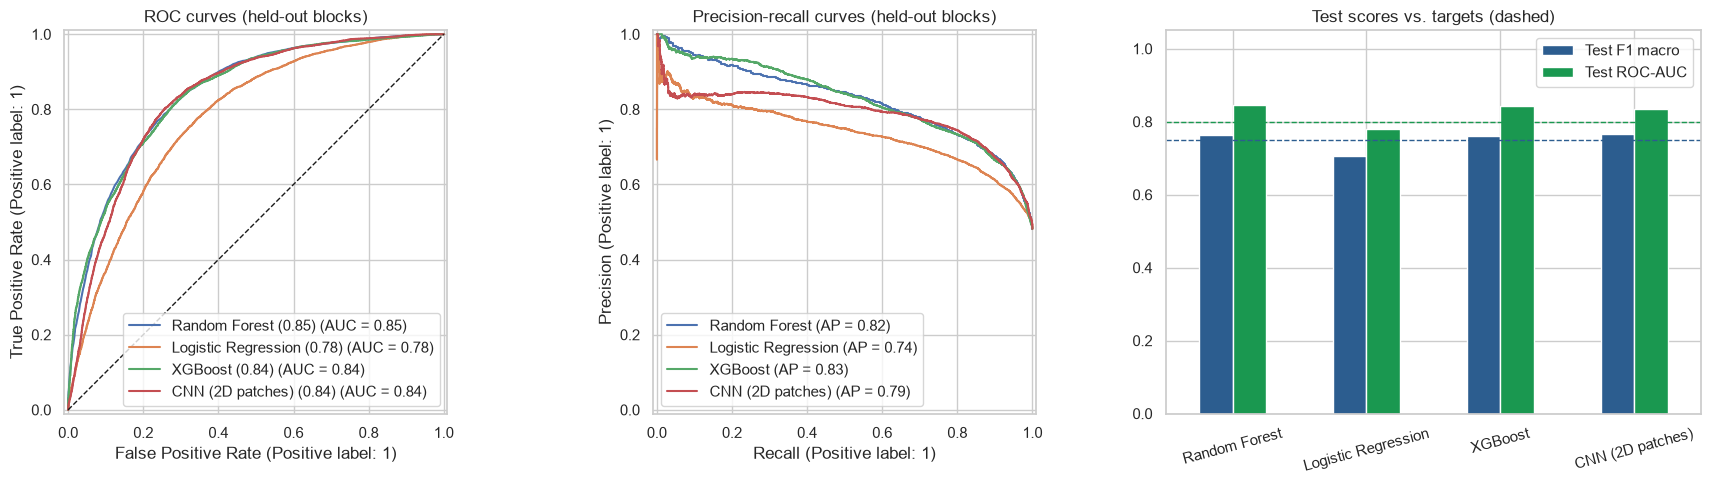

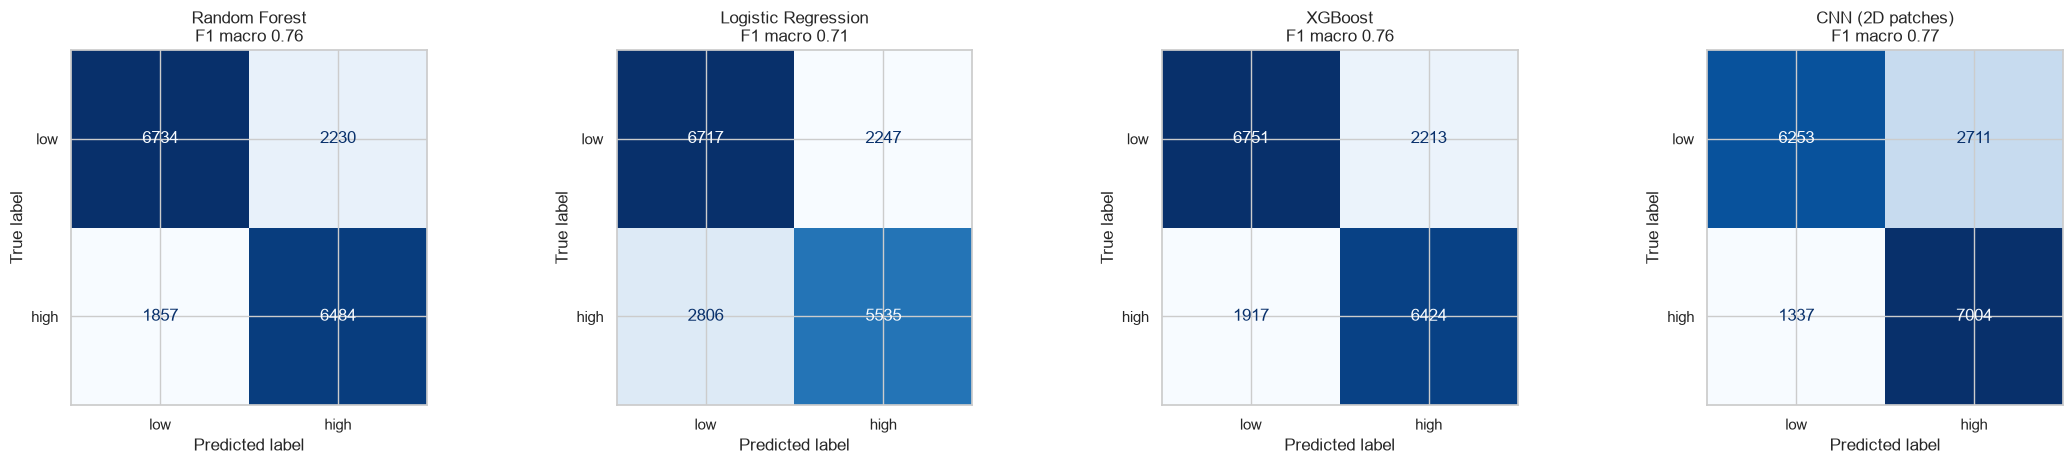

In [25]:
# ============================ 8. COMPARISON PLOTS ============================
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for name in proba:
    RocCurveDisplay.from_predictions(y_te_a, proba[name], ax=ax[0], name=f"{name} ({res.loc[name, 'Test ROC-AUC']:.2f})")
    PrecisionRecallDisplay.from_predictions(y_te_a, proba[name], ax=ax[1], name=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curves (held-out blocks)")
ax[1].set_title("Precision-recall curves (held-out blocks)")
res[["Test F1 macro", "Test ROC-AUC"]].plot.bar(ax=ax[2], rot=15, color=["#2c5d8f", "#1a9850"])
ax[2].axhline(0.75, color="#2c5d8f", ls="--", lw=1); ax[2].axhline(0.80, color="#1a9850", ls="--", lw=1)
ax[2].set_ylim(0, 1.05); ax[2].set_title("Test scores vs. targets (dashed)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES / "05a_model_comparison.png", dpi=300); plt.show()

fig, ax = plt.subplots(1, len(proba), figsize=(5.5 * len(proba), 4.8))
for a, name in zip(np.atleast_1d(ax), proba):
    ConfusionMatrixDisplay(confusion_matrix(y_te_a, pred[name]), display_labels=["low", "high"]).plot(
        ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{name}\nF1 macro {res.loc[name, 'Test F1 macro']:.2f}")
plt.tight_layout(); plt.savefig(FIGURES / "05b_confusion_matrices.png", dpi=300); plt.show()

# FEATURE IMPORTANCE

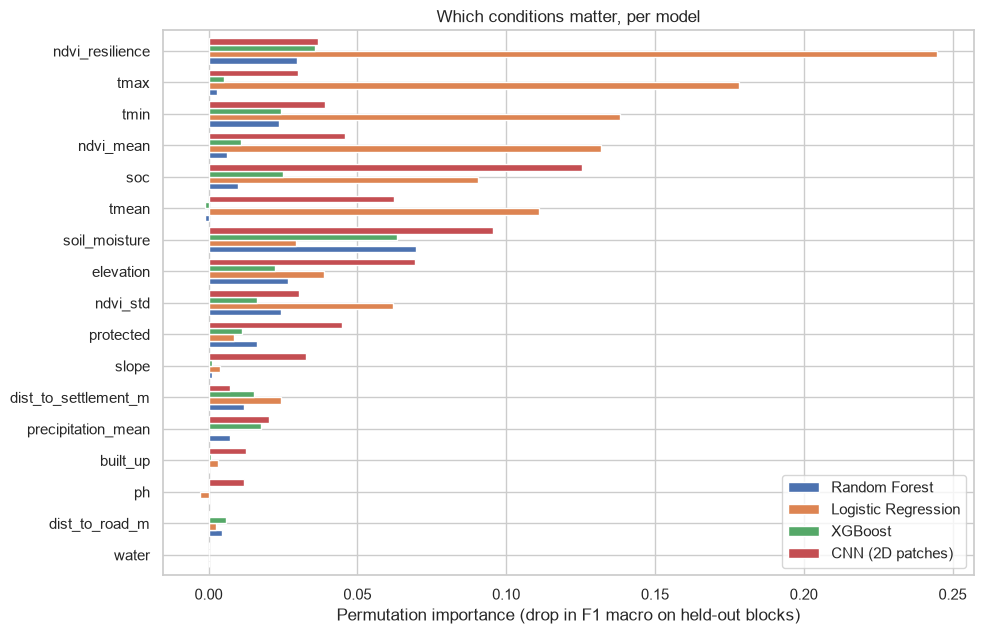


Permutation importance (held-out):
                      Random Forest  Logistic Regression  XGBoost  CNN (2D patches)
soil_moisture                 0.070                0.029    0.063             0.096
ndvi_resilience               0.030                0.245    0.036             0.037
elevation                     0.027                0.039    0.022             0.069
ndvi_std                      0.024                0.062    0.016             0.030
tmin                          0.024                0.138    0.024             0.039
protected                     0.016                0.009    0.011             0.045
dist_to_settlement_m          0.012                0.024    0.015             0.007
soc                           0.010                0.090    0.025             0.126
precipitation_mean            0.007                0.000    0.018             0.020
ndvi_mean                     0.006                0.132    0.011             0.046
dist_to_road_m                0.005     

In [26]:
# ============================ 9. FEATURE IMPORTANCE (permutation, held-out blocks, same metric for every model) ============================
from sklearn.pipeline import Pipeline

def _final(est):
    """Unwrap a Pipeline to its last (fitted) step; pass plain estimators through."""
    return est[-1] if isinstance(est, Pipeline) else est


def cnn_layer_importance(model, n_repeats=10):
    """Shuffle one whole input layer (a full patch channel, or a scalar feature) across the test samples."""
    core = _final(model).core_                      # works whether the CNN is wrapped or not
    P_t, _ = PATCH_STORE.get(X_te.index)
    S_t = X_te[list(SCALAR_FEATURES)].to_numpy(np.float32).reshape(len(X_te), -1)
    rng = np.random.RandomState(RANDOM_STATE)
    base = macro_f1(y_te_a, core.predict_proba(P_t, S_t))

    out = {}
    for j, nm in enumerate(PATCH_BANDS):            # shuffle whole patch channels
        drops = []
        for _ in range(n_repeats):
            Pp = P_t.copy(); Pp[:, j] = Pp[rng.permutation(len(Pp)), j]
            drops.append(base - macro_f1(y_te_a, core.predict_proba(Pp, S_t)))
        out[nm] = np.mean(drops)

    for j, nm in enumerate(SCALAR_FEATURES):        # shuffle scalar columns of the CNN branch
        drops = []
        for _ in range(n_repeats):
            Sp = S_t.copy(); Sp[:, j] = Sp[rng.permutation(len(Sp)), j]
            drops.append(base - macro_f1(y_te_a, core.predict_proba(P_t, Sp)))
        out[nm] = np.mean(drops)

    return pd.Series(out).reindex(PREDICTORS)


N_REPEATS   = 5          # 20 -> 5: stable enough, 4x cheaper
N_JOBS_PERM = 1          # <- KEY FIX: no loky process pool -> no pickling, no RAM explosion
                         #    (want parallel? wrap the call in joblib.parallel_backend("threading") and use n_jobs=4)

perm = {}
for name, m in fitted.items():
    if hasattr(_final(m), "core_"):                 # spatial patch CNN -> shuffle whole input layers
        perm[name] = cnn_layer_importance(m, n_repeats=N_REPEATS)
    else:                                           # table-based models (RF, LR, XGB)
        r = permutation_importance(m, X_te, y_te_a, scoring="f1_macro",
                                   n_repeats=N_REPEATS, random_state=RANDOM_STATE,
                                   n_jobs=N_JOBS_PERM)
        perm[name] = pd.Series(r.importances_mean, index=X_te.columns).reindex(PREDICTORS)

perm = pd.DataFrame(perm)
perm = perm.loc[perm.max(axis=1).sort_values().index]
perm.plot.barh(figsize=(10, 6.5), width=0.8)
plt.xlabel("Permutation importance (drop in F1 macro on held-out blocks)")
plt.title("Which conditions matter, per model")
plt.tight_layout(); plt.savefig(FIGURES / "06_feature_importance.png", dpi=300); plt.show()
print("\nPermutation importance (held-out):")
print(perm.sort_values(perm.columns[0], ascending=False).round(3))

if "Logistic Regression" in fitted:                 # direction of each effect (standardised units)
    lr = _final(fitted["Logistic Regression"])      # robust to step renames ("clf" vs "model")
    coef = pd.Series(lr.coef_[0], index=PREDICTORS)
    print("\nLogistic regression coefficients (+ = more likely high potential):")
    print(coef.sort_values(key=abs, ascending=False).round(3))

# MODELS WITH OPPORTUNITY SCORES

In [27]:
# ============================ 10. SAVE MODELS + OPPORTUNITY SCORES ============================
cnn_core = fitted[CNN_NAME].core_
joblib.dump({"models": {k: v for k, v in fitted.items() if k != CNN_NAME}, "best": best_name,
             "features": PREDICTORS, "label_col": LABEL_COL, "low_threshold": float(lo),
             "high_threshold": float(hi), "results": res}, DATA_PROCESSED / "models.pkl")
torch.save({"state_dict": cnn_core.net_.state_dict(), "params": fitted[CNN_NAME].get_params(deep=False) | {"store": None},
            "channels": PATCH_BANDS, "scalars": SCALAR_FEATURES, "radius": R, "mu": cnn_core.mu_, "sd": cnn_core.sd_,
            "smu": cnn_core.smu_, "ssd": cnn_core.ssd_}, DATA_PROCESSED / "patch_cnn.pt")
joblib.dump(fitted[best_name], DATA_PROCESSED / "best_model.pkl")

ok = data[PREDICTORS].notna().all(axis=1).values
for name, m in fitted.items():                                   # every model, the CNN included, scores the same way
    data["opportunity_" + slug(name)] = np.nan
    data.loc[ok, "opportunity_" + slug(name)] = m.predict_proba(data.loc[ok, PREDICTORS])[:, 1]
data["opportunity"] = data["opportunity_" + slug(best_name)]     # P(high potential), 0-1
print(f"\nSaved models.pkl, patch_cnn.pt, best_model.pkl | scores for {ok.sum()} points")


Saved models.pkl, patch_cnn.pt, best_model.pkl | scores for 99913 points


# THE MAPS 

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D

# ============================ SETTINGS ============================
POINT_SIZE = 7            # marker size of the points
CMAP = "RdYlGn"           # red = low potential, green = high potential
HIGH_T, LOW_T = 0.60, 0.40   # tiers: >= 0.60 high | <= 0.40 low | in between uncertain
HEX_GRID = 40             # number of hexagons across the map (smaller = coarser)
HEX_MIN_POINTS = 3        # a hexagon is drawn only if it contains at least this many points

In [29]:
# ============================ DATA FOR THE MAPS ============================
score_cols = {name: "opportunity_" + slug(name) for name in fitted}          # one score column per model
m = data.loc[data[list(score_cols.values())].notna().all(axis=1)]            # points that have predictions
lon, lat = m.geometry.x.values, m.geometry.y.values                          # EPSG:4326
best = m["opportunity"].values
print(f"Mapped points: {len(m)} of {len(data)} (the rest are excluded areas or have missing inputs)")

def style(ax, title):
    ax.set_title(title, fontsize=11)
    ax.set_aspect(1 / np.cos(np.deg2rad(lat.mean())))                        # keep the true shape of the region
    ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    try:
        aoi_gdf.boundary.plot(ax=ax, color="black", linewidth=0.8)           # outline of the study area
    except Exception:
        pass


    

Mapped points: 99913 of 99913 (the rest are excluded areas or have missing inputs)


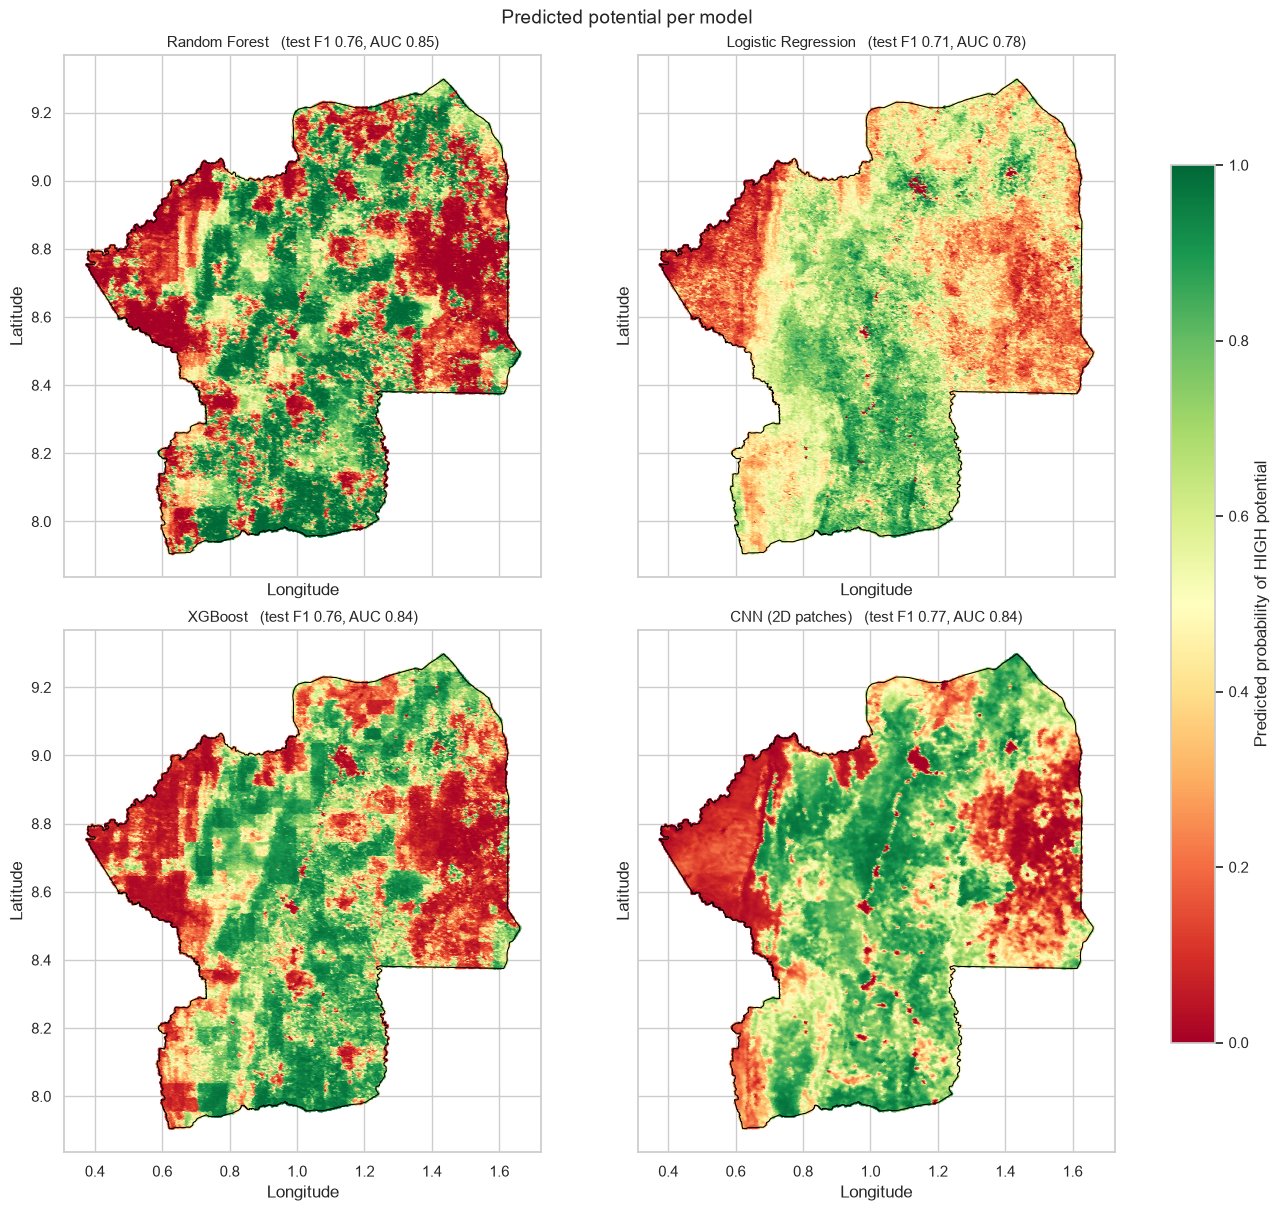

In [30]:
# ============================ FIGURE 1: ONE MAP PER MODEL ============================
n = len(score_cols); ncols = 2; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 6 * nrows), sharex=True, sharey=True, layout="constrained")
axes = np.atleast_1d(axes).ravel()
for ax, (name, col) in zip(axes, score_cols.items()):
    sc = ax.scatter(lon, lat, c=m[col].values, s=POINT_SIZE, cmap=CMAP, vmin=0, vmax=1, linewidths=0)
    style(ax, f"{name}   (test F1 {res.loc[name, 'Test F1 macro']:.2f}, AUC {res.loc[name, 'Test ROC-AUC']:.2f})")
for ax in axes[n:]:
    ax.set_visible(False)
fig.colorbar(sc, ax=list(axes[:n]), shrink=0.8, label="Predicted probability of HIGH potential")
fig.suptitle("Predicted potential per model", fontsize=14)
fig.savefig(FIGURES / "07a_maps_per_model.png", dpi=300); plt.show()

# BEST MODEL

Low potential (<= 0.4)      :  41.9%  |      5,548 km²
Uncertain (0.4-0.6)         :  11.1%  |      1,465 km²
High potential (>= 0.6)     :  47.0%  |      6,228 km²


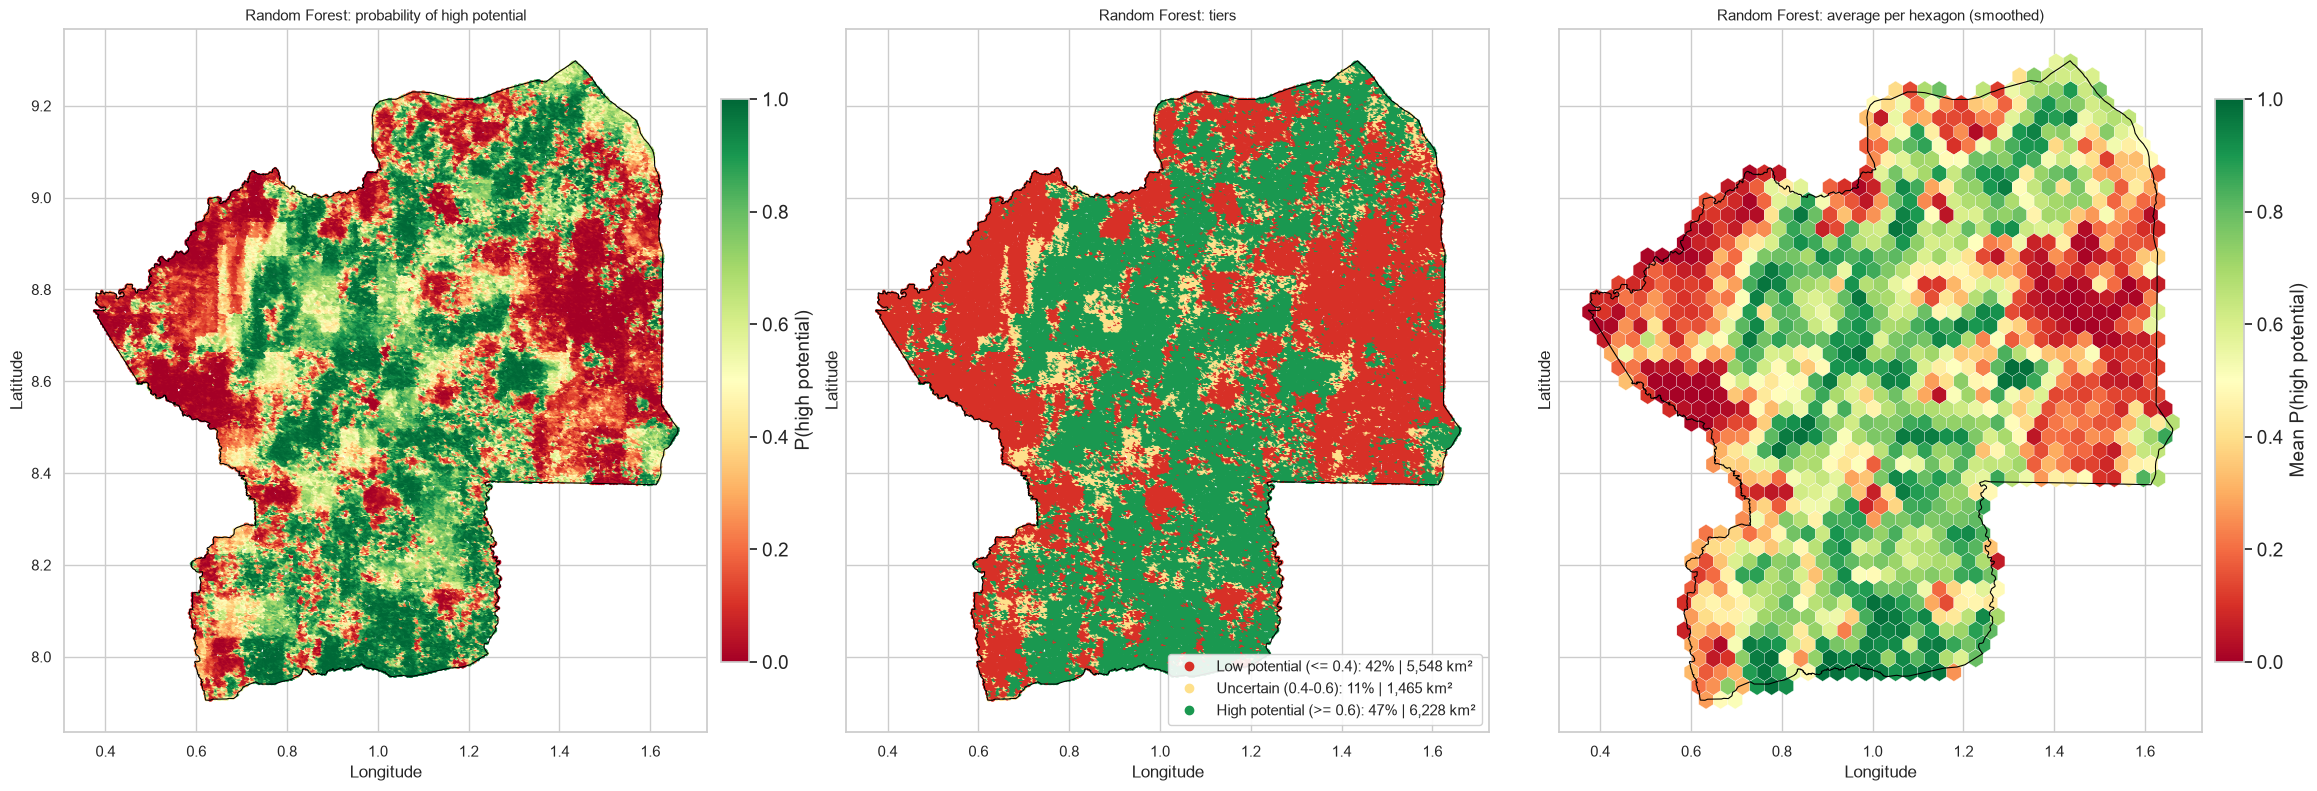

In [31]:
# ============================ FIGURE 2: BEST MODEL (continuous | tiers | smoothed) ============================
# ---- Tier areas: each uniformly-sampled point represents an equal share of the frame ----
tier = np.where(best >= HIGH_T, 2, np.where(best <= LOW_T, 0, 1))

utm_crs   = aoi_gdf.estimate_utm_crs()
frame_km2 = aoi_gdf.to_crs(utm_crs).geometry.union_all().area / 1e6     # study-frame area
counts    = np.bincount(tier, minlength=3)
tier_km2  = counts / tier.size * frame_km2                              # km² per tier

tier_colors = ["#d73027", "#fee08b", "#1a9850"]
labels = [f"Low potential (<= {LOW_T})", f"Uncertain ({LOW_T}-{HIGH_T})", f"High potential (>= {HIGH_T})"]
for k, l in enumerate(labels):
    print(f"{l:28s}: {counts[k]/tier.size*100:5.1f}%  |  {tier_km2[k]:9,.0f} km²")

# ============================ FIGURE 2 (with km² in legend) ============================
fig, ax = plt.subplots(1, 3, figsize=(23, 7.8), sharex=True, sharey=True, layout="constrained")

sc = ax[0].scatter(lon, lat, c=best, s=POINT_SIZE, cmap=CMAP, vmin=0, vmax=1, linewidths=0)
style(ax[0], f"{best_name}: probability of high potential")
cb1 = fig.colorbar(sc, ax=ax[0], location="right", shrink=0.8, pad=0.02)
cb1.set_label("P(high potential)", fontsize=14); cb1.ax.tick_params(labelsize=14)

ax[1].scatter(lon, lat, c=tier, s=POINT_SIZE, cmap=ListedColormap(tier_colors),
              vmin=0, vmax=2, linewidths=0)
style(ax[1], f"{best_name}: tiers")
ax[1].legend(
    handles=[Line2D([], [], marker="o", ls="", color=c,
                    label=f"{l}: {(tier == k).mean()*100:.0f}% | {tier_km2[k]:,.0f} km²")
             for k, (c, l) in enumerate(zip(tier_colors, labels))],
    loc="lower right", fontsize=11, framealpha=0.9)

hb = ax[2].hexbin(lon, lat, C=best, gridsize=HEX_GRID, reduce_C_function=np.mean,
                  mincnt=HEX_MIN_POINTS, cmap=CMAP, vmin=0, vmax=1, 
                  linewidths=0.2, edgecolors="white")
style(ax[2], f"{best_name}: average per hexagon (smoothed)")
cb2 = fig.colorbar(hb, ax=ax[2], location="right", shrink=0.8, pad=0.02)
cb2.set_label("Mean P(high potential)", fontsize=14); cb2.ax.tick_params(labelsize=14)

fig.savefig(FIGURES / "07b_map_best_model.png", dpi=300, bbox_inches="tight"); plt.show()

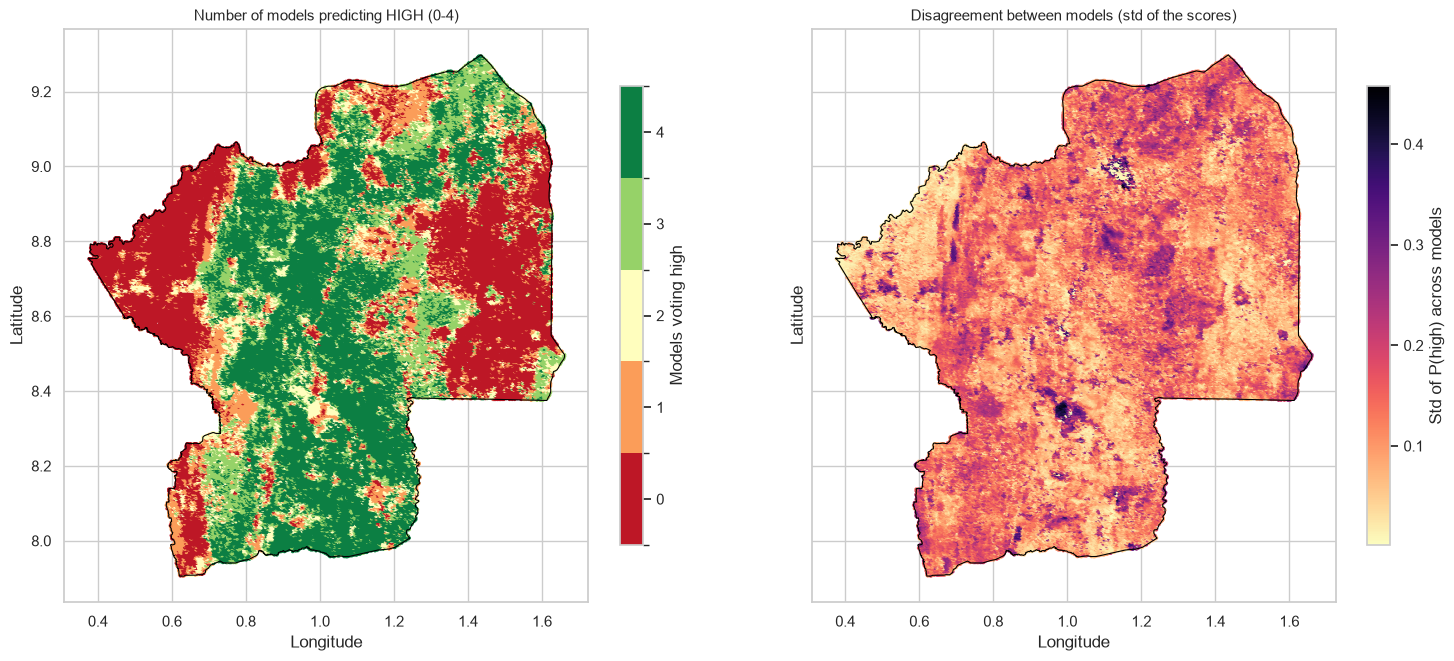


Share of points by number of models voting HIGH:
0    27.2
1    12.3
2    10.1
3    16.1
4    34.2


In [32]:
# ============================ FIGURE 3: WHERE DO THE MODELS AGREE? ============================
S_all = m[list(score_cols.values())].to_numpy()
votes = (S_all >= 0.5).sum(axis=1)                                           # how many models say "high"
spread = S_all.std(axis=1)                                                   # disagreement between the models

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
vote_cmap = ListedColormap(plt.get_cmap("RdYlGn")(np.linspace(0.05, 0.95, n + 1)))
sc = ax[0].scatter(lon, lat, c=votes, s=POINT_SIZE, cmap=vote_cmap, norm=BoundaryNorm(np.arange(-0.5, n + 1.5), n + 1), linewidths=0)
style(ax[0], f"Number of models predicting HIGH (0-{n})")
cb = fig.colorbar(sc, ax=ax[0], shrink=0.8, ticks=range(n + 1)); cb.set_label("Models voting high")
sp = ax[1].scatter(lon, lat, c=spread, s=POINT_SIZE, cmap="magma_r", linewidths=0)
style(ax[1], "Disagreement between models (std of the scores)")
fig.colorbar(sp, ax=ax[1], shrink=0.8, label="Std of P(high) across models")
fig.savefig(FIGURES / "07c_map_model_agreement.png", dpi=300); plt.show()
print("\nShare of points by number of models voting HIGH:")
print(pd.Series(votes).value_counts(normalize=True).sort_index().mul(100).round(1).rename("%").to_string())

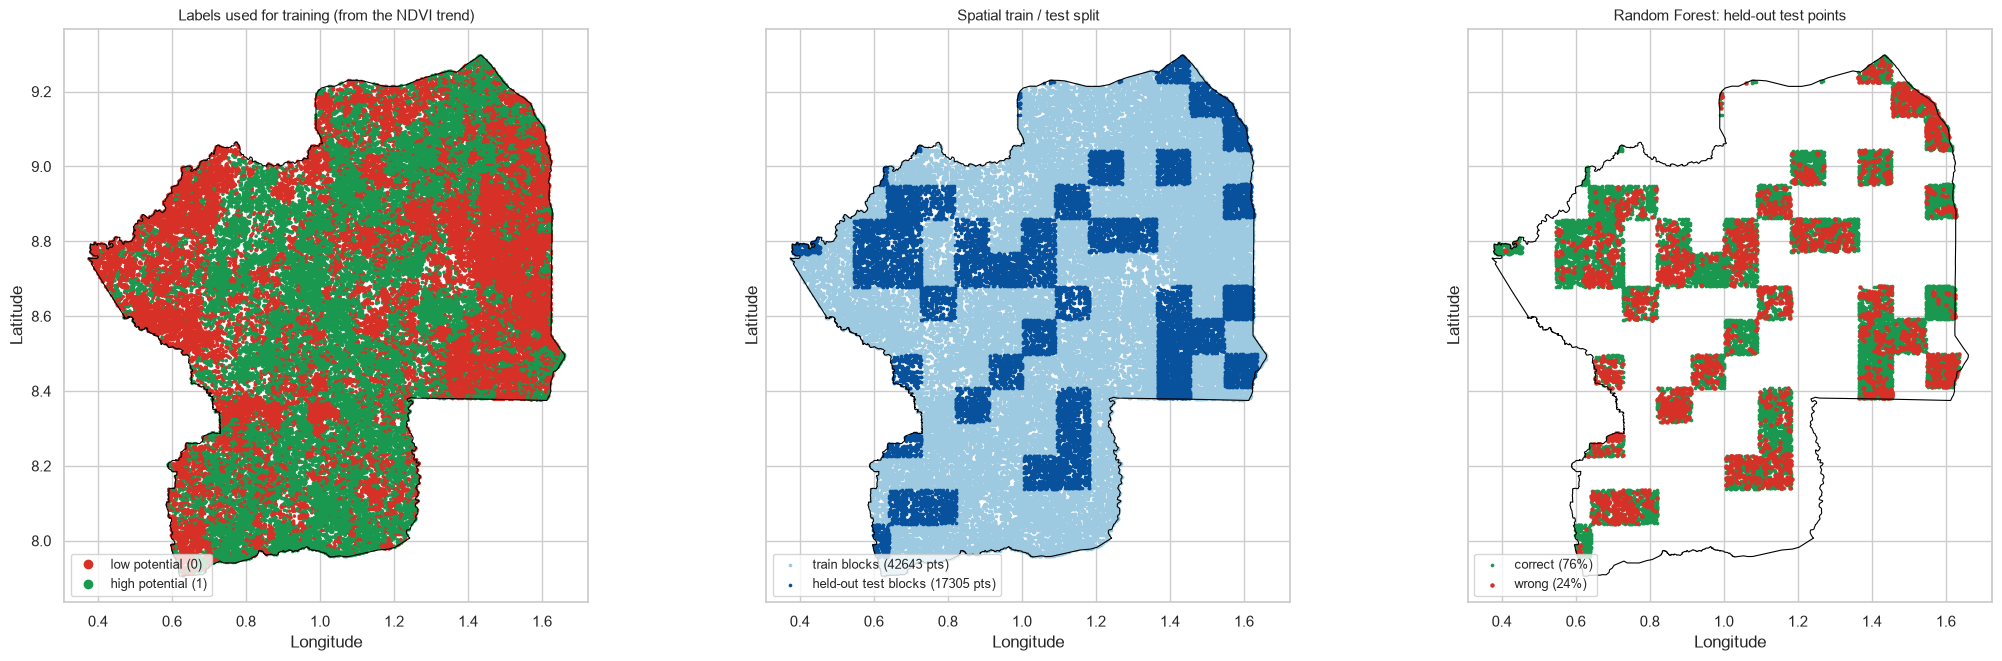

In [33]:
# ============================ FIGURE 4: LABELS, SPLIT AND ERRORS (held-out blocks) ============================
d_lon, d_lat = d.geometry.x.values, d.geometry.y.values
is_test = np.zeros(len(d), dtype=bool); is_test[te] = True
d_te = d.iloc[te]
correct = (pred[best_name] == y_te_a)

fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), sharex=True, sharey=True, layout="constrained")
ax[0].scatter(d_lon, d_lat, c=d["label"].values, s=POINT_SIZE, cmap=ListedColormap(["#d73027", "#1a9850"]), vmin=0, vmax=1, linewidths=0)
style(ax[0], "Labels used for training (from the NDVI trend)")
ax[0].legend(handles=[Line2D([], [], marker="o", ls="", color="#d73027", label="low potential (0)"),
                      Line2D([], [], marker="o", ls="", color="#1a9850", label="high potential (1)")], loc="lower left", fontsize=9)

ax[1].scatter(d_lon[~is_test], d_lat[~is_test], s=POINT_SIZE, color="#9ecae1", linewidths=0, label=f"train blocks ({(~is_test).sum()} pts)")
ax[1].scatter(d_lon[is_test], d_lat[is_test], s=POINT_SIZE, color="#08519c", linewidths=0, label=f"held-out test blocks ({is_test.sum()} pts)")
style(ax[1], "Spatial train / test split")
ax[1].legend(loc="lower left", fontsize=9)

ax[2].scatter(d_te.geometry.x.values[correct], d_te.geometry.y.values[correct], s=POINT_SIZE, color="#1a9850", linewidths=0,
              label=f"correct ({correct.mean() * 100:.0f}%)")
ax[2].scatter(d_te.geometry.x.values[~correct], d_te.geometry.y.values[~correct], s=POINT_SIZE * 1.5, color="#d73027", linewidths=0,
              label=f"wrong ({(~correct).mean() * 100:.0f}%)")
style(ax[2], f"{best_name}: held-out test points")
ax[2].legend(loc="lower left", fontsize=9)
fig.savefig(FIGURES / "07d_map_labels_split_errors.png", dpi=300); plt.show()

In [34]:
# ============================ OPTIONAL: SAVE FOR QGIS ============================
try:
    m[["geometry", "opportunity", *score_cols.values()]].to_file(DATA_PROCESSED / "predictions.gpkg", driver="GPKG")
    print(f"\nSaved predictions for QGIS: {DATA_PROCESSED / 'predictions.gpkg'}")
except Exception as e:
    print("Could not save the GeoPackage:", str(e)[:100])


Saved predictions for QGIS: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED\predictions.gpkg


# COST AND RETURN

Every investable site is costed for two general land uses, **forest restoration** (carbon credits, plus fuelwood from year 6 and shea kernels from year 15) and **agriculture** (generic cereal benchmark). All values are per hectare, in USD, over a horizon of $T$ = 20 years with a discount rate $r$ = 10 % (both set in the cell below). The sources for every input are listed in `references/cost_return_sources/README.md`.

**Cost**: present value of all costs: establishment, maintenance, access (walking to the site, carrying loads from the road), erosion control, fire treatment and liming.

**Expected return**: present value of the revenue if the land use succeeds, × the model's probability of high potential (`opportunity`), reduced by fire risk.

**Net present value (NPV)**: all money in and out over the horizon, converted to today's value. A dollar received in year $t$ is worth $1/(1+r)^t$ today (at $r$ = 10 %, 1 USD next year is worth 0.91 USD today):

$$\text{NPV} = \sum_{t=1}^{T} \frac{\text{expected revenue}_t - \text{cost}_t}{(1+r)^t} = \text{expected return} - \text{cost}$$

NPV > 0: the land use pays back its costs **and** earns more than the discount rate. NPV < 0: it does not.

**Return on investment (ROI)**: the net gain per dollar invested, in today's money:

$$\text{ROI} = \frac{\text{NPV}}{\text{cost}}$$

ROI = 25 % means every 1 USD invested brings back 1.25 USD; ROI = −40 % means only 0.60 USD comes back. Sites are ranked by the ROI of their better land use.

**Average income per year**: the forest earns nothing at first (carbon from year 4, fuelwood from year 6, shea from year 15), so its income in full production (142 USD/ha/yr) overstates what it earns over the horizon. The cell below also prints the average per year in today's money, the present value of the revenue divided by the present value of 1 USD per year:

$$\text{income per year} = \frac{\sum_{t=1}^{T} \text{revenue}_t / (1+r)^t}{\sum_{t=1}^{T} 1 / (1+r)^t}$$

The **Cost and return** page of the web app uses the same inputs and shows this value as *Forest income*. Its sidebar lets you change the forest establishment and maintenance cost, the crop production cost, the farm wage and the discount rate (0-20 %), each starting at the value used here.

Forest income in full production (USD/ha/yr): {'Carbon credits': 112, 'Shea kernels': 17, 'Fuelwood': 24, 'Carbon lost to fuelwood': -11} | total 142
Forest restoration : revenue if successful 142 USD/ha/yr in full production | yearly cost 50 USD/ha | establishment 680 USD/ha
Agriculture        : revenue if successful 346 USD/ha/yr in full production | yearly cost 161 USD/ha | establishment 121 USD/ha
Investable points: 77968 of 99913 | each point represents 13 ha
Forest restoration : PV of revenue if successful 755 USD/ha (= 89 USD/ha per year in today's money, as the app's income) | mean cost 1,003 USD/ha | mean NPV -638 USD/ha
Agriculture        : PV of revenue if successful 2,945 USD/ha (= 346 USD/ha per year in today's money, as the app's income) | mean cost 2,236 USD/ha | mean NPV -771 USD/ha

Sites ranked: 141 | profitable (best ROI > 0): 25
Best use (all sites): {'Agriculture': 141}


,rank,best_use,best_roi,area_ha,opportunity,fire_freq,slope,dist_road_km,cost_ha_forest_restoration,npv_ha_forest_restoration,roi_forest_restoration,cost_ha_agriculture,npv_ha_agriculture,roi_agriculture,best_total_cost_musd,best_total_npv_musd,lon,lat
block,,,,,,,,,,,,,,,,,,
28_89,1,Agriculture,50%,"9,450",0.93,0.05,1.4,0.8,931,-252,-27%,"1,806",896,50%,17.07,8.47,1.048,8.090
29_88,2,Agriculture,41%,"8,257",0.85,0.06,1.1,0.7,933,-314,-34%,"1,762",717,41%,14.55,5.92,1.137,8.009
35_93,3,Agriculture,32%,928,0.83,0.04,1.1,1.0,937,-323,-34%,"1,841",593,32%,1.71,0.55,1.647,8.486
30_88,4,Agriculture,32%,"3,313",0.76,0.02,1.1,0.8,906,-337,-37%,"1,701",537,32%,5.64,1.78,1.207,8.016
28_88,5,Agriculture,31%,"9,410",0.87,0.11,1.4,1.1,975,-362,-37%,"1,915",587,31%,18.02,5.53,1.050,8.004
28_95,6,Agriculture,26%,"9,649",0.83,0.02,1.5,0.7,929,-313,-34%,"1,920",505,26%,18.53,4.87,1.047,8.634
27_90,7,Agriculture,23%,"8,032",0.77,0.02,1.9,0.6,911,-337,-37%,"1,831",424,23%,14.71,3.40,0.961,8.174
30_96,8,Agriculture,14%,"9,861",0.80,0.05,1.1,0.7,964,-381,-39%,"2,032",289,14%,20.04,2.85,1.226,8.728
32_101,9,Agriculture,12%,"9,861",0.84,0.03,1.2,1.6,974,-348,-36%,"2,207",266,12%,21.76,2.62,1.407,9.178


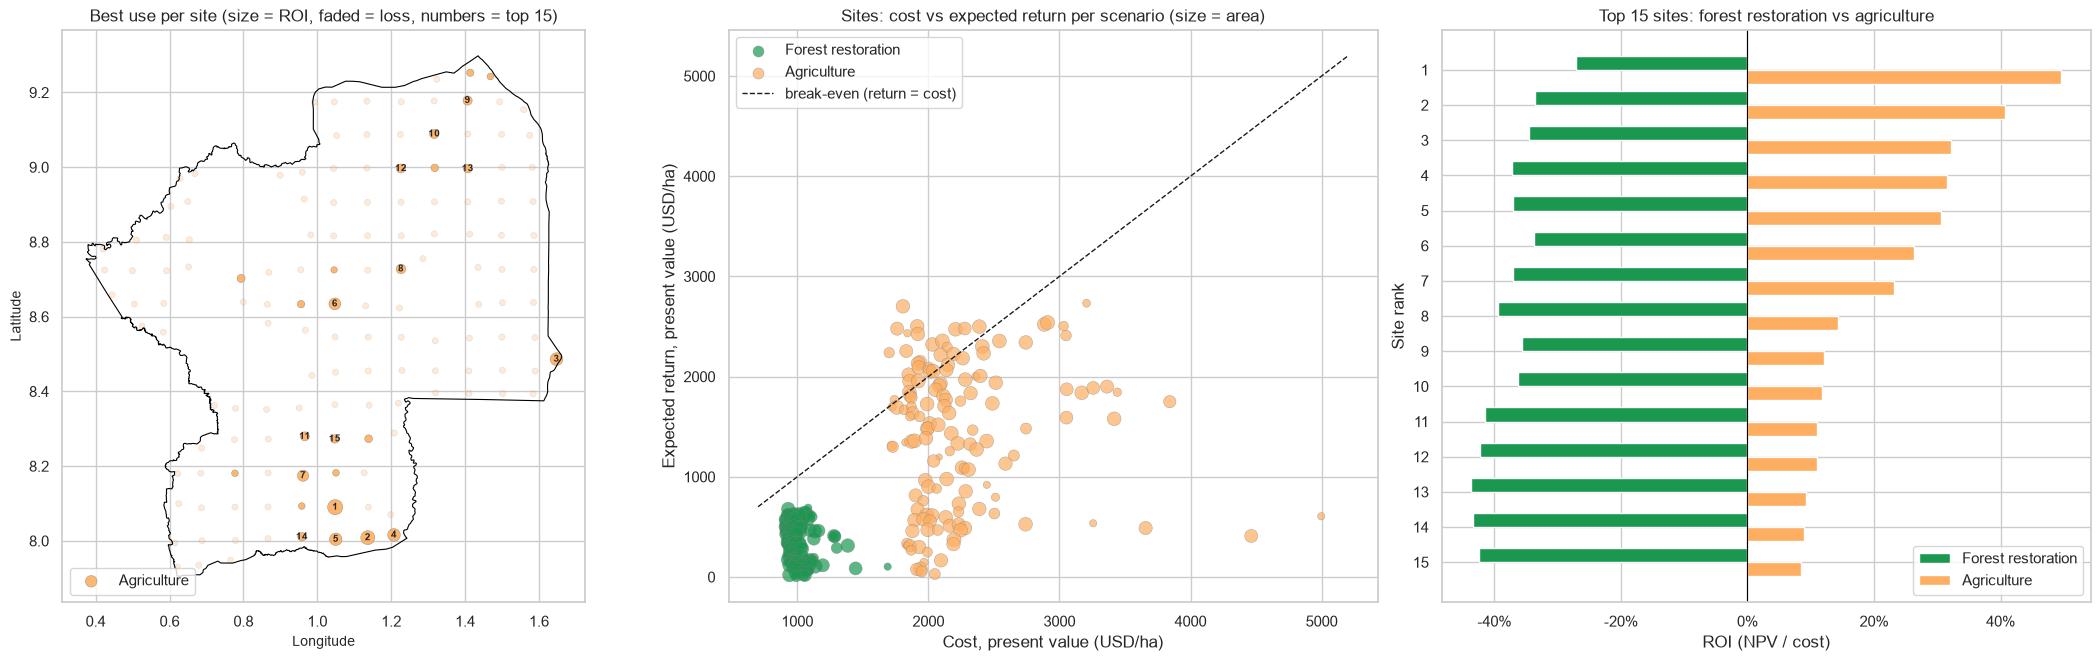

Saved: c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\data\DATA_PROCESSED\site_ranking_cost_return.csv and c:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\reports\FIGURES\cost_return_ranking.png


In [35]:
# ============================ 11. COST AND RETURN: RANK SITES FOR INVESTORS ============================
# Two general land-use scenarios are costed for every point (no specific crop or tree species):
#   - Forest restoration : assisted natural regeneration / planting -> carbon credits + fuelwood + shea kernels
#   - Agriculture        : yearly cropping (staple cereal used as the generic benchmark) -> farm income
# Cost per hectare = establishment (base + site conditions) + yearly costs, discounted to a present value.
# Expected return per hectare = opportunity score x revenue if successful, reduced by fire risk, discounted.
# Points are grouped into the 10 km spatial blocks ("sites"); each site gets both scenarios + the better one.
# Values come from the reference datasets cited next to them; lines marked ASSUMPTION have no reference yet.

# ============================ REFERENCE DATA ============================
XOF_PER_USD = 600      # World Bank WDI PA.NUS.FCRF (official rate), Togo 2022-2025: 624 / 607 / 606 / 582

# ---- Forest carbon: IPCC 2019 Refinement, Vol. 4 Ch. 4 (Forest Land) ----
AGB_GROWTH_T_DM = 3.9  # Table 4.9: above-ground growth, Africa, tropical dry forest, secondary <= 20 yr (t d.m./ha/yr)
                       #   (tropical moist deciduous forest, Africa: 2.9 - use it for the wetter south of the AOI)
ROOT_SHOOT = 0.332     # Table 4.4: below/above-ground ratio R, Africa, tropical dry forest, natural, AGB <= 125 t/ha
CARBON_FRACTION = 0.47 # IPCC 2006, Vol. 4 Table 4.3: carbon fraction of dry matter, tropical forest
CREDIT_SHARE = 0.8     # ASSUMPTION: share of removals sold after the buffer pool / uncertainty deductions
CO2_T_HA_YR = AGB_GROWTH_T_DM * (1 + ROOT_SHOOT) * CARBON_FRACTION * 44 / 12   # ~8.9 tCO2e/ha/yr
CARBON_PRICE = 15.6    # Ecosystem Marketplace, State of the VCM 2023, Table 4: ARR credits, avg USD/tCO2e
                       #   2023 (2021: 7.97, 2022: 11.79)

# ---- Forest restoration costs: Bodin et al. 2021, FAO "The Economics of Ecosystem Restoration" (Restor. Ecol.
#      30: e13515): assisted natural regeneration 12-3,880 USD/ha establishment, 2-213 USD/ha/yr maintenance (yr 1-5).
#      FAO & AUDA-NEPAD 2021, Review of forest and landscape restoration in Africa: Ethiopia 87-1,445 USD/ha,
#      Madagascar 680 USD/ha, farmer-managed natural regeneration 40-50 USD/ha. ----
FOREST_EST_COST = 680  # FAO & AUDA-NEPAD 2021 (Madagascar; inside the Ethiopia range)
FOREST_MAINT_COST = 50 # Bodin et al. 2021 range 2-213 USD/ha/yr
FOREST_MAINT_YRS = 5   # Bodin et al. 2021 report maintenance for years 1-5

# ---- Forest products besides carbon: shea kernels and fuelwood (README files 18-21) ----
SHEA_KERNEL_KG_HA = 60   # Bockel et al. 2020 (FAO & Global Shea Alliance), Table 4: improved parklands, 0.060 t/ha
SHEA_USD_KG = 23.96 / 85 # same report, Table 6: price of an 85-kg bag of kernels sold by collecting women
SHEA_START_YR = 15       # same report, p. 3: shea starts fruiting at about 15 years (Hofer 2009)
FUELWOOD_M3_HA = 1.0     # de Montalembert & Clement 1983, FAO Forestry Paper 42, ch. IV: wooded savanna 0.8-1.2 m3/ha/yr
FUELWOOD_T_M3 = 696_256.94 / 838_863.78  # Kaina et al. 2020, Region Centrale: tonnes / m3 of fuelwood produced
FUELWOOD_XOF_KG = 23.6   # same study: mean fuelwood price, Region Centrale 2019-2020 (range 20-28 FCFA/kg)
WOOD_DENSITY = 0.53      # IPCC 2006, Vol. 4 Table 4.13: Daniellia oliveri, a Guinea-savanna species (t d.m./m3)
FUELWOOD_START_YR = 6    # ASSUMPTION: first harvest after the maintenance years
FUELWOOD_CO2_HA = FUELWOOD_M3_HA * WOOD_DENSITY * CARBON_FRACTION * 44 / 12   # harvested wood is burnt: not credited

# ---- Agriculture: generic cereal benchmark for Togo ----
CROP_YIELD_KG_HA = 1198  # World Bank WDI AG.YLD.CREL.KG (source: FAO), Togo cereal yield 2024 (2018-2023: 1,143-1,197)
CROP_PRICE_XOF_KG = 231  # WFP market prices (HDX "wfp_food_prices_tgo"): median retail maize, Centrale markets, 2021-2026
FARMGATE_SHARE = 0.75    # ASSUMPTION: producer price vs retail (press reports producer prices <= 180 FCFA/kg)
CROP_COST_XOF_HA = 96_700  # production cost per ha, Togo 2022 (La Cinquieme, 2024); cross-check: DSID net income
                           #   223,000 FCFA/ha (2018-19 campaign, via TogoDailyNews 2020)

# ---- Site extras (distance, slope, fire, soil acidity) ----
WAGE_XOF_H = 302.89      # Togo SMIG = SMAG (agricultural minimum wage), 52,500 FCFA/month, decree of 1 Jan 2023
WORKDAY_H = 8            # 52,500 / 302.89 = 173 h/month = 40-h week -> 8-h day
WAGE_USD_DAY = WAGE_XOF_H * WORKDAY_H / XOF_PER_USD   # ~4 USD/day
WALK_KMH = 5.0           # Tobler (1993) hiking function on flat ground (~5 km/h)
HEADLOAD_USD_TKM = 1.5   # head-loading / last-mile carrying: Starkey et al. (2002), cited in Hine (2014), World Bank
                         #   SSATP Working Paper 100, p. 43 (trucks on rural roads: ~0.2 USD/t-km)
CROP_LABOUR_DAYS = 88    # Amegbeto (FAO), "Etude comparative de rentabilite ... au Togo", Table 9: manual maize,
                         #   person-days/ha/yr (Kara and Centrale regions; yield 1,188 kg/ha)
CLEARING_DAYS = 30       # same study, Table 14: manual clearing 12,000-18,000 FCFA/ha at a SMAG of 499 FCFA/day
FOREST_LABOUR_DAYS = 100 # FAO SFM Toolbox, Forest restoration module: 50-150 person-days/ha, years 1-3
SEEDLINGS_HA = 1000      # Trillion Trees (2022) p. 8: ~1,000 trees per hectare in tropical planting
SEEDLING_KG = 1.0        # ASSUMPTION: potted seedling incl. soil
BUND_DAYS = 75           # Critchley (1991), "Looking after our land" (Oxfam/IIED, FAO): stone bunds 50-100 person-days/ha
FIRE_TREAT_USD_HA = 62.02  # Barnes et al. (2020), fuel management in Ghana's forests: prescribed burning, USD/ha
LIME_USD_T = 107         # Jaleta et al. (2024), AfJARE 19(1): unsubsidised agricultural lime, USD/t (Rwanda)
LIME_T_HA = 0.86         # same study: average lime rate on maize fields
LIME_EFFECT_YRS = 4      # same study: yield effect fades over 4 seasons (ASSUMPTION: one main season per year)

# ============================ SETTINGS ============================
# Income per hectare per year in full production (USD/ha/yr) and the first year it is paid
FOREST_INCOME_LINES = {
    "Carbon credits":          (CO2_T_HA_YR * CREDIT_SHARE * CARBON_PRICE, 4),   # ASSUMPTION: first credit issuance in year 4
    "Shea kernels":            (SHEA_KERNEL_KG_HA * SHEA_USD_KG, SHEA_START_YR),
    "Fuelwood":                (FUELWOOD_M3_HA * FUELWOOD_T_M3 * 1000 * FUELWOOD_XOF_KG * FARMGATE_SHARE / XOF_PER_USD,
                                FUELWOOD_START_YR),
    "Carbon lost to fuelwood": (-FUELWOOD_CO2_HA * CREDIT_SHARE * CARBON_PRICE, FUELWOOD_START_YR),   # the wood is burnt
}
FOREST_INCOME_HA_YR = sum(usd for usd, _ in FOREST_INCOME_LINES.values())   # ~142 USD/ha/yr
CROP_INCOME_LINES = {"Crop sales": (CROP_YIELD_KG_HA * CROP_PRICE_XOF_KG * FARMGATE_SHARE / XOF_PER_USD, 1)}

SCENARIOS = {
    "Forest restoration": dict(
        base_cost_ha       = FOREST_EST_COST,
        yearly_cost_ha     = FOREST_MAINT_COST,
        yearly_cost_yrs    = FOREST_MAINT_YRS,
        labour_days        = FOREST_LABOUR_DAYS,           # walked to the site from the nearest settlement
        haul_t             = SEEDLINGS_HA * SEEDLING_KG / 1000,  # carried in from the nearest road
        access_yearly      = False,  # one establishment campaign
        bund_cost_ha       = 0,      # tree cover itself controls erosion - no bunds
        fire_cost_ha_yr    = FIRE_TREAT_USD_HA,   # x fire_freq: fuel treatment in the years the site burns
        lime_cost_ha       = 0,      # native species are adapted to local soils - no liming
        income_lines       = FOREST_INCOME_LINES,   # carbon from year 4, fuelwood from year 6, shea from year 15
        fire_loss          = 0.6,    # ASSUMPTION: share of the return lost at fire_freq = 1 (young trees burn)
    ),
    "Agriculture": dict(
        base_cost_ha       = CLEARING_DAYS * WAGE_USD_DAY,   # one-off clearing of degraded land
        yearly_cost_ha     = CROP_COST_XOF_HA / XOF_PER_USD,
        yearly_cost_yrs    = None,   # every year of the horizon
        labour_days        = CROP_LABOUR_DAYS,
        haul_t             = CROP_YIELD_KG_HA / 1000,        # harvest carried out to the road
        access_yearly      = True,   # farmers walk / carry every season
        bund_cost_ha       = BUND_DAYS * WAGE_USD_DAY,       # contour stone bunds on sloping fields
        fire_cost_ha_yr    = 0,      # fields are cleared every season, so fuel is already managed
        lime_cost_ha       = LIME_T_HA * LIME_USD_T,         # repeated every LIME_EFFECT_YRS on acidic soils
        income_lines       = CROP_INCOME_LINES,     # harvest sold every year
        fire_loss          = 0.2,    # ASSUMPTION: yearly crops recover quickly after fire
    ),
}
SLOPE_FREE_DEG   = 2       # ASSUMPTION: erosion control (bunds) needed above this slope (~3.5 %)
LOW_PH           = 5.5     # acidic soil threshold (Jaleta et al. 2024 / Haile et al. 2023: liming trials on pH < 5.5)
HORIZON_YRS      = 20      # investment horizon
DISCOUNT_RATE    = 0.10    # ASSUMPTION: typical rate for development-project appraisal
MIN_SITE_HA      = 500     # a site needs at least this much investable land
TOP_N            = 15      # sites shown in the table / bar chart
SCEN_COLORS      = {"Forest restoration": "#1a9850", "Agriculture": "#fdae61"}
print("Forest income in full production (USD/ha/yr):",
      {k: round(v) for k, (v, _) in FOREST_INCOME_LINES.items()}, f"| total {FOREST_INCOME_HA_YR:,.0f}")
for name, s in SCENARIOS.items():
    full = sum(usd for usd, _ in s['income_lines'].values())
    print(f"{name:<19}: revenue if successful {full:,.0f} USD/ha/yr in full production | "
          f"yearly cost {s['yearly_cost_ha']:,.0f} USD/ha | establishment {s['base_cost_ha']:,.0f} USD/ha")

# ============================ 1. INVESTABLE POINTS + AREA PER POINT ============================
excluded = (data[["protected", "water", "built_up"]].fillna(0) > 0).any(axis=1)
inv = data.loc[~excluded & data["opportunity"].notna()].copy()
frame_ha = aoi_gdf.to_crs(utm).geometry.union_all().area / 1e4
ha_per_point = frame_ha / len(data)                                 # uniform sample: each point = equal share of the frame
print(f"Investable points: {len(inv)} of {len(data)} | each point represents {ha_per_point:,.0f} ha")

years = np.arange(1, HORIZON_YRS + 1)
disc = 1 / (1 + DISCOUNT_RATE) ** years                              # discount factor per year
fire = inv["fire_freq"].fillna(0)
d_settle_km = inv["dist_to_settlement_m"] / 1000
d_road_km = inv["dist_to_road_m"] / 1000
pv_lime = disc[(years - 1) % LIME_EFFECT_YRS == 0].sum()               # lime applied in year 1, 5, 9, ...

# ============================ 2. COST + RETURN PER HECTARE, PER SCENARIO ============================
for name, s in SCENARIOS.items():
    k = slug(name)
    access = (s["labour_days"] * 2 * d_settle_km / WALK_KMH * WAGE_XOF_H / XOF_PER_USD   # walking time, round trip
              + s["haul_t"] * d_road_km * HEADLOAD_USD_TKM)                             # carrying loads from the road
    once = (s["base_cost_ha"]
            + np.where(inv["slope"] > SLOPE_FREE_DEG, s["bund_cost_ha"], 0)
            + (0 if s["access_yearly"] else access))
    every_year = s["fire_cost_ha_yr"] * fire + (access if s["access_yearly"] else 0)
    maint = disc if s["yearly_cost_yrs"] is None else disc[years <= s["yearly_cost_yrs"]]
    yearly_rev = sum(np.where(years >= start, usd, 0.0) for usd, start in s["income_lines"].values())
    pv_rev = (yearly_rev * disc).sum()                                           # PV of revenue if successful
    inv[f"cost_ha_{k}"]   = (once + s["yearly_cost_ha"] * maint.sum() + every_year * disc.sum()
                             + np.where(inv["ph"] < LOW_PH, s["lime_cost_ha"], 0) * pv_lime)   # PV of all costs
    inv[f"return_ha_{k}"] = inv["opportunity"] * (1 - s["fire_loss"] * fire) * pv_rev
    inv[f"npv_ha_{k}"]    = inv[f"return_ha_{k}"] - inv[f"cost_ha_{k}"]
    print(f"{name:<19}: PV of revenue if successful {pv_rev:,.0f} USD/ha "
          f"(= {pv_rev / disc.sum():,.0f} USD/ha per year in today's money, as the app's income) | "
          f"mean cost {inv[f'cost_ha_{k}'].mean():,.0f} USD/ha | mean NPV {inv[f'npv_ha_{k}'].mean():,.0f} USD/ha")

# ============================ 3. AGGREGATE TO SITES (10 km blocks) ============================
inv["lon"], inv["lat"] = inv.geometry.x, inv.geometry.y
metric_cols = [c for c in inv.columns if c.startswith(("cost_ha_", "return_ha_", "npv_ha_"))]
sites = inv.groupby("block").agg(n_points=("opportunity", "size"), lon=("lon", "mean"), lat=("lat", "mean"),
                                 opportunity=("opportunity", "mean"), fire_freq=("fire_freq", "mean"),
                                 slope=("slope", "mean"),
                                 dist_road_km=("dist_to_road_m", lambda v: v.mean() / 1000),
                                 **{c: (c, "mean") for c in metric_cols})
sites["area_ha"] = sites["n_points"] * ha_per_point
sites = sites[sites["area_ha"] >= MIN_SITE_HA].copy()
for name in SCENARIOS:
    k = slug(name)
    sites[f"roi_{k}"] = sites[f"npv_ha_{k}"] / sites[f"cost_ha_{k}"]
    sites[f"total_npv_musd_{k}"] = sites[f"npv_ha_{k}"] * sites["area_ha"] / 1e6

# ============================ 4. BEST USE PER SITE + RANK ============================
roi_cols = {name: f"roi_{slug(name)}" for name in SCENARIOS}
sites["best_use"] = sites[list(roi_cols.values())].idxmax(axis=1).map({v: k for k, v in roi_cols.items()})
sites["best_roi"] = sites[list(roi_cols.values())].max(axis=1)
sites["best_total_cost_musd"] = [sites.at[i, f"cost_ha_{slug(u)}"] * sites.at[i, "area_ha"] / 1e6
                                 for i, u in sites["best_use"].items()]
sites["best_total_npv_musd"] = [sites.at[i, f"total_npv_musd_{slug(u)}"] for i, u in sites["best_use"].items()]
sites = sites.sort_values("best_roi", ascending=False)
sites.insert(0, "rank", np.arange(1, len(sites) + 1))

print(f"\nSites ranked: {len(sites)} | profitable (best ROI > 0): {(sites['best_roi'] > 0).sum()}")
print("Best use (all sites):", sites["best_use"].value_counts().to_dict())
show = ["rank", "best_use", "best_roi", "area_ha", "opportunity", "fire_freq", "slope", "dist_road_km",
        *[c for n in SCENARIOS for c in (f"cost_ha_{slug(n)}", f"npv_ha_{slug(n)}", f"roi_{slug(n)}")],
        "best_total_cost_musd", "best_total_npv_musd", "lon", "lat"]
fmt = {c: "{:,.0f}" for c in show if c.startswith(("cost_ha_", "npv_ha_")) or c == "area_ha"}
fmt |= {c: "{:.0%}" for c in show if "roi" in c}
fmt |= {"opportunity": "{:.2f}", "fire_freq": "{:.2f}", "slope": "{:.1f}", "dist_road_km": "{:.1f}",
        "best_total_cost_musd": "{:.2f}", "best_total_npv_musd": "{:.2f}", "lon": "{:.3f}", "lat": "{:.3f}"}
display(sites[show].head(TOP_N).style.format(fmt).background_gradient(subset=["best_roi"], cmap="RdYlGn"))

# ============================ 5. PLOTS ============================
top = sites.head(TOP_N)
fig, ax = plt.subplots(1, 3, figsize=(21, 6.5), layout="constrained")

# (a) map: best use per site, marker size = ROI, top sites numbered
for name, col in SCEN_COLORS.items():
    s = sites[sites["best_use"] == name]
    if s.empty:
        continue
    ax[0].scatter(s["lon"], s["lat"], c=col, s=20 + 200 * s["best_roi"].clip(lower=0),
                  alpha=np.where(s["best_roi"] > 0, 0.9, 0.25), edgecolors="grey", linewidths=0.3, label=name)
for _, r in top.iterrows():
    ax[0].annotate(int(r["rank"]), (r["lon"], r["lat"]), fontsize=7, ha="center", va="center", weight="bold")
ax[0].set_aspect(1 / np.cos(np.deg2rad(sites["lat"].mean())))
try:
    aoi_gdf.boundary.plot(ax=ax[0], color="black", linewidth=0.8)
except Exception:
    pass
ax[0].set_title(f"Best use per site (size = ROI, faded = loss, numbers = top {TOP_N})")
ax[0].set_xlabel("Longitude"); ax[0].set_ylabel("Latitude"); ax[0].legend(loc="lower left")

# (b) cost vs expected return, both scenarios
for name, col in SCEN_COLORS.items():
    k = slug(name)
    ax[1].scatter(sites[f"cost_ha_{k}"], sites[f"return_ha_{k}"], c=col, s=np.sqrt(sites["area_ha"]),
                  alpha=0.7, edgecolors="grey", linewidths=0.3, label=name)
xy = np.array([ax[1].get_xlim()[0], ax[1].get_xlim()[1]])
ax[1].plot(xy, xy, "k--", lw=1, label="break-even (return = cost)")
ax[1].set_xlabel("Cost, present value (USD/ha)"); ax[1].set_ylabel("Expected return, present value (USD/ha)")
ax[1].set_title("Sites: cost vs expected return per scenario (size = area)"); ax[1].legend()

# (c) top sites: ROI of both scenarios side by side
yy, h = np.arange(len(top)), 0.4
for j, (name, col) in enumerate(SCEN_COLORS.items()):
    ax[2].barh(yy + (j - 0.5) * h, top[f"roi_{slug(name)}"], height=h, color=col, label=name)
ax[2].set_yticks(yy, top["rank"].astype(str)); ax[2].invert_yaxis()
ax[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax[2].axvline(0, color="black", lw=0.8)
ax[2].set_xlabel("ROI (NPV / cost)"); ax[2].set_ylabel("Site rank")
ax[2].set_title(f"Top {TOP_N} sites: forest restoration vs agriculture"); ax[2].legend()
fig.savefig(FIGURES / "cost_return_ranking.png", dpi=150)
plt.show()

# ============================ 6. SAVE ============================
sites.to_csv(DATA_PROCESSED / "site_ranking_cost_return.csv")
print(f"Saved: {DATA_PROCESSED / 'site_ranking_cost_return.csv'} and {FIGURES / 'cost_return_ranking.png'}")

# STREAMLIT DEPLOYMENT AND WEB MAP

Three cells:

1. **Web map**: builds the interactive folium map `reports/FIGURES/interactive/interactive_map.html` with one layer per model, tiers, hexagons, country borders, three basemaps and a mini-map (on Esri tiles: OpenStreetMap's own tile server blocks maps opened as a local file).
2. **Open the saved web map** in the browser, without re-running the notebook.
3. **Start the web app** at https://agrorestoreai in the background, without a console window (`app/launcher.py`; outside the notebook, double-click **Start AgroRestore AI**). Besides the results of this notebook, the app can score any new region: it samples the same layers from Earth Engine, measures the OpenStreetMap distances, checks every model against the region's own NDVI trend and fine-tunes the CNN on it (`app/adapt.py`).

In [36]:
# %%
# =====================================================================================================
# Interactive map (folium): wall-to-wall layers, tiers, excluded zones, HEXAGONS, COUNTRY BORDERS, click-for-details.
# =====================================================================================================
import json
import math
import re
import os
import webbrowser
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import geopandas as gpd
import shapely.geometry as sg
from PIL import Image
from scipy.spatial import cKDTree
import folium
from folium.plugins import Fullscreen, MiniMap, MousePosition, MeasureControl
from branca.colormap import LinearColormap
from branca.element import MacroElement
from jinja2 import Template

# ============================ SETTINGS ============================
HIGH_T, LOW_T = globals().get("HIGH_T", 0.60), globals().get("LOW_T", 0.40)
OPEN_IN_BROWSER = True                         
SHOW_INLINE = False                            
OUTPUTS = FIGURES / "interactive"
OUTPUTS.mkdir(parents=True, exist_ok=True)

slug = globals().get("slug") or (lambda s: re.sub(r"\W+", "_", s.lower()).strip("_"))
CMAP = plt.get_cmap("RdYlGn")                  
TIER_NAMES = {0: "Low potential", 1: "Uncertain", 2: "High potential"}
TIER_COLORS = {0: "#d73027", 1: "#fee08b", 2: "#1a9850"}
ZONE_LIST = ["free", "protected", "water", "urban", "no data"]
ZONE_COLORS = {"protected": "#9e9e9e", "water": "#6baed6", "urban": "#fd8d3c", "no data": "#e0e0e0"}
ZONE_LABELS = {"protected": "Protected area (excluded - conserve)", "water": "Water (excluded)",
               "urban": "Urban (excluded)", "no data": "No data"}

# ============================ 1. DATA: grid or sampled points ============================
if "grid_df" in globals() and "grid" in globals():
    cols = {n: "score_" + slug(n) for n in fitted if "score_" + slug(n) in grid_df.columns}
    lon, lat = grid.geometry.x.to_numpy(), grid.geometry.y.to_numpy()
    zone = grid_df["zone"].to_numpy().astype(object)
    scores = {n: grid_df[c].to_numpy(dtype=float) for n, c in cols.items()}
    spacing_m, reach, cell_km2 = float(GRID_M), 0.75, (GRID_M / 1000) ** 2
    source = f"wall-to-wall grid ({GRID_M} m)"
else:
    cols = {n: "opportunity_" + slug(n) for n in fitted if "opportunity_" + slug(n) in data.columns}
    m_ = data.loc[data[list(cols.values())].notna().all(axis=1)]
    lon, lat = m_.geometry.x.to_numpy(), m_.geometry.y.to_numpy()
    zone = np.full(len(m_), "free", dtype=object)
    scores = {n: m_[c].to_numpy(dtype=float) for n, c in cols.items()}
    aoi_km2 = aoi_gdf.to_crs(aoi_gdf.estimate_utm_crs()).area.sum() / 1e6
    spacing_m, reach, cell_km2 = math.sqrt(aoi_km2 * 1e6 / len(lon)), 1.2, aoi_km2 / len(lon)
    source = f"sampled points ({len(lon)})"

assert scores, "No score columns found. Run the grid cell (or the training script) first."

MAP_MODEL = globals().get("MAP_MODEL") if globals().get("MAP_MODEL") in scores else (best_name if best_name in scores else list(scores)[0])
free = (zone == "free")
best_s = scores[MAP_MODEL]
tier = np.where(best_s >= HIGH_T, 2, np.where(best_s <= LOW_T, 0, 1))
tier_counts = {k: int(((tier == k) & free).sum()) for k in (0, 1, 2)}
tier_km2 = {k: tier_counts[k] * cell_km2 for k in tier_counts}
zone_km2 = {z: int((zone == z).sum()) * cell_km2 for z in ZONE_LIST[1:]}
print(f"Source: {source} | map model: {MAP_MODEL} | free cells: {int(free.sum())} | tier km2: { {TIER_NAMES[k]: round(v) for k, v in tier_km2.items()} }")

# ============================ 2. WALL-TO-WALL IMAGES (PNG overlays) ============================
lat0 = float(lat.mean()); kx = math.cos(math.radians(lat0))
deg_lat = spacing_m / 111_320.0                                   
west, east = lon.min() - deg_lat / kx / 2, lon.max() + deg_lat / kx / 2
south, north = lat.min() - deg_lat / 2, lat.max() + deg_lat / 2
px = deg_lat / 3                                                  
px *= max(1.0, max((east - west) / (px / kx), (north - south) / px) / 2500)      
W, Hh = int(np.ceil((east - west) / (px / kx))), int(np.ceil((north - south) / px))
CX, CY = np.meshgrid(west + (np.arange(W) + 0.5) * px / kx, north - (np.arange(Hh) + 0.5) * px)
tree = cKDTree(np.column_stack([lon * kx, lat]))                  
dist, idx = tree.query(np.column_stack([CX.ravel() * kx, CY.ravel()]), distance_upper_bound=reach * deg_lat)
inside = np.isfinite(dist)

def to_png(cell_rgba, name):
    img = np.zeros((Hh * W, 4), dtype=np.uint8)
    img[inside] = cell_rgba[idx[inside]]
    path = OUTPUTS / f"_layer_{name}.png"
    Image.fromarray(img.reshape(Hh, W, 4), "RGBA").save(path)
    return str(path)

def zone_rgba(rgba):                                               
    for z, hexc in ZONE_COLORS.items():
        rgba[zone == z] = [*(int(c * 255) for c in mcolors.to_rgb(hexc)), 215]
    return rgba

layer_png = {}
for name, s in scores.items():
    rgba = (CMAP(np.nan_to_num(s, nan=0.0)) * 255).astype(np.uint8); rgba[..., 3] = 215
    layer_png[name] = to_png(zone_rgba(rgba), slug(name))
    
t_rgba = np.zeros((len(lon), 4), dtype=np.uint8)
for k, hexc in TIER_COLORS.items():
    t_rgba[tier == k] = [*(int(c * 255) for c in mcolors.to_rgb(hexc)), 215]
tier_png = to_png(zone_rgba(t_rgba), "tiers")
bounds = [[south, west], [north, east]]

# ============================ 2.5 HEXBIN LAYER (Random Forest average per hexagon) ============================
HEX_GRID = globals().get("HEX_GRID", 50)
HEX_MIN_POINTS = globals().get("HEX_MIN_POINTS", 1)
rf_name = "Random Forest" if "Random Forest" in scores else MAP_MODEL
rf_scores = scores[rf_name]

valid = np.isfinite(rf_scores)
hex_lon, hex_lat, hex_s = lon[valid], lat[valid], rf_scores[valid]
hex_gdf = None

if len(hex_s) > 0:
    fig, ax_h = plt.subplots()
    hb = ax_h.hexbin(hex_lon, hex_lat, C=hex_s, gridsize=HEX_GRID, 
                     reduce_C_function=np.mean, mincnt=HEX_MIN_POINTS)
    plt.close(fig)
    
    paths = hb.get_paths()
    offsets = hb.get_offsets()
    values = hb.get_array()
    
    n_hex = min(len(offsets), len(values))
    offsets = offsets[:n_hex]
    values = values[:n_hex]
    
    polys = []
    if len(paths) == 1:
        base_vertices = paths[0].vertices
        polys = [sg.Polygon(base_vertices + off) for off in offsets]
    else:
        polys = [sg.Polygon(p.vertices + off) for p, off in zip(paths, offsets)]
        
    hex_gdf = gpd.GeoDataFrame({'mean_score': np.round(values, 3), 'geometry': polys}, crs="EPSG:4326")
    print(f"✅ Generated {len(hex_gdf)} hexagons for {rf_name} average.")

# ============================ 2.6 COUNTRY LIMITS (Robust with GEE Fallback) ============================
countries_gdf = None
possible_shps = ["data/world_countries.shp", "data/cameroon.shp", "data/burkina_faso.shp", "world_countries.shp", "data/countries_near_aoi.shp"]

for shp in possible_shps:
    if os.path.exists(shp):
        try:
            world = gpd.read_file(shp).to_crs("EPSG:4326")
            minx, miny, maxx, maxy = aoi_gdf.to_crs("EPSG:4326").total_bounds
            countries_gdf = world.cx[minx-2 : maxx+2, miny-2 : maxy+2]
            if len(countries_gdf) >= 1:
                print(f"✅ Loaded country borders from {shp}")
                break
        except Exception as e:
            pass # silently try next

# Fallback: fetch neighbouring countries straight from GEE if local file missing
if countries_gdf is None or len(countries_gdf) == 0:
    try:
        import ee, geemap
        minx, miny, maxx, maxy = aoi_gdf.to_crs("EPSG:4326").total_bounds
        rect = ee.Geometry.Rectangle(minx - 2, miny - 2, maxx + 2, maxy + 2)
        near = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017").filterBounds(rect)
        countries_gdf = geemap.ee_to_gdf(near).to_crs("EPSG:4326")
        countries_gdf.to_file("data/countries_near_aoi.shp")
        print(f"✅ Downloaded {len(countries_gdf)} countries from GEE as fallback.")
    except Exception as e:
        print(f"⚠️ GEE fallback failed ({e}). Country borders will be skipped.")

# ============================ 3. CLICK HANDLER ============================
def click_js():
    payload = {"lon": [round(float(v), 5) for v in lon], "lat": [round(float(v), 5) for v in lat],
               "zone": [ZONE_LIST.index(z) if z in ZONE_LIST else 0 for z in zone],
               "names": list(scores), "zones": [ZONE_LABELS.get(z, z) for z in ZONE_LIST],
               "s": [[-1 if not np.isfinite(v) else int(round(v * 100)) for v in s] for s in scores.values()],
               "best": list(scores).index(MAP_MODEL), "hi": HIGH_T, "lo": LOW_T,
               "pal": [mcolors.to_hex(CMAP(i / 100)) for i in range(101)]}
    body = ("""function(map) {
  try {
    var D = __PAYLOAD__;
    var kx = __KX__, reach = __REACH__;
    function nearest(lng, lat) {
      var b = -1, bd = 1e18;
      for (var i = 0; i < D.lon.length; i++) {
        var dx = (D.lon[i] - lng) * kx, dy = D.lat[i] - lat, d = dx * dx + dy * dy;
        if (d < bd) { bd = d; b = i; }
      }
      return (Math.sqrt(bd) <= reach) ? b : -1;
    }
    function tierOf(p) { return p >= D.hi ? 'High potential' : (p <= D.lo ? 'Low potential' : 'Uncertain'); }
    function popupHtml(i) {
      var h = '<div style="font-size:13px;min-width:230px"><b>' + D.lat[i].toFixed(4) + ', ' + D.lon[i].toFixed(4) + '</b><br>';
      if (D.zone[i] !== 0) { return h + '<i>' + D.zones[D.zone[i]] + '</i><br>Not scored by the models.</div>'; }
      var pb = D.s[D.best][i] / 100;
      h += 'Tier (' + D.names[D.best] + '): <b>' + tierOf(pb) + '</b><hr style="margin:4px 0">';
      for (var m = 0; m < D.names.length; m++) {
        var v = D.s[m][i];
        if (v < 0) { continue; }
        h += '<div>' + D.names[m] + ': <b>' + (v / 100).toFixed(2) + '</b>' +
             '<div style="height:6px;width:' + v + '%;background:' + D.pal[v] + ';border-radius:3px"></div></div>';
      }
      return h + '</div>';
    }
    map.on('click', function(e) {
      var i = nearest(e.latlng.lng, e.latlng.lat);
      if (i < 0) { return; }
      L.popup({maxWidth: 340}).setLatLng(e.latlng).setContent(popupHtml(i)).openOn(map);
    });
  } catch (err) { console.error('Click handler failed:', err); }
}""").replace("__PAYLOAD__", json.dumps(payload, separators=(",", ":"))).replace("__KX__", repr(kx)).replace("__REACH__", repr(reach * deg_lat))
    assert not re.search(r"\{\{|\{%|\{#|#\}|%\}", body), "the script contains a Jinja2 delimiter"
    return body

class ClickInfo(MacroElement):
    _template = Template("{% macro script(this, kwargs) %}({{ this.js }})({{ this._parent.get_name() }});{% endmacro %}")
    def __init__(self, js):
        super().__init__()
        self._name = "ClickInfo"
        self.js = js

# ============================ 4. THE MAP ============================
def make_interactive_map():
    # tiles=None -> prevents broken default basemaps
    fmap = folium.Map(location=[lat0, float(lon.mean())], zoom_start=9,
                      tiles=None, control_scale=True, prefer_canvas=True)

    # Key-free, demo-friendly basemaps:
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri", name="Streets (Esri)", show=True).add_to(fmap)

    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri", name="Satellite (Esri)", show=False).add_to(fmap)

    folium.TileLayer(
        tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
        attr="&copy; OpenStreetMap contributors | Style &copy; OpenTopoMap (CC-BY-SA)",
        name="OpenTopoMap", show=False, max_zoom=17).add_to(fmap)

    # 1. Image Overlays (Models & Tiers)
    for name, path in layer_png.items():
        folium.raster_layers.ImageOverlay(
            image=path, bounds=bounds, opacity=0.9,
            name=f"{name}: probability of high potential",
            show=(name == MAP_MODEL), interactive=False, zindex=2
        ).add_to(fmap)

    folium.raster_layers.ImageOverlay(
        image=tier_png, bounds=bounds, opacity=0.9, show=False, interactive=False, zindex=3,
        name=f"{MAP_MODEL}: tiers (" + ", ".join(f"{TIER_NAMES[k]} {tier_km2[k]:,.0f} km2" for k in (0, 1, 2)) + ")"
    ).add_to(fmap)

    # 2. Country Borders (Added BEFORE AOI so AOI outline sits on top)
    if countries_gdf is not None and not countries_gdf.empty:
        folium.GeoJson(
            countries_gdf.__geo_interface__,
            name="Country borders",
            show=True,
            style_function=lambda f: {"fill": False, "color": "#111111", "weight": 2.0, "dashArray": "6, 4", "opacity": 0.9}
        ).add_to(fmap)
        print("✅ Country borders layer added to map.")
    else:
        print("⚠️ Country borders layer skipped (no data available).")

    # 3. Hexbin Layer
    if hex_gdf is not None and not hex_gdf.empty:
        def hex_style(feature):
            score = feature['properties']['mean_score']
            color = mcolors.to_hex(CMAP(score))
            return {'fillColor': color, 'color': 'white', 'weight': 0.8, 'fillOpacity': 0.75}

        folium.GeoJson(
            hex_gdf.__geo_interface__,
            name=f"{rf_name}: average per hexagon",
            show=False,
            style_function=hex_style,
            tooltip=folium.GeoJsonTooltip(
                fields=['mean_score'], aliases=['Avg P(high):'], localize=True,
                style="font-size: 12px; font-weight: bold;"
            )
        ).add_to(fmap)

    # 4. Study Area (AOI) - Always on top
    folium.GeoJson(
        aoi_gdf.to_crs("EPSG:4326").__geo_interface__,
        name="Study area (AOI)",
        show=True,
        style_function=lambda f: {"fill": False, "color": "black", "weight": 2.5}
    ).add_to(fmap)

    # 5. Controls & Legend
    LinearColormap([mcolors.to_hex(CMAP(v)) for v in np.linspace(0, 1, 7)], vmin=0, vmax=1,
                   caption="Probability of HIGH potential").add_to(fmap)
    Fullscreen().add_to(fmap)
    # Esri tiles, not the OpenStreetMap default: tile.openstreetmap.org blocks pages opened as a local file
    # (no Referer header), which shows its yellow-black "Access blocked" tile in the mini-map.
    MiniMap(tile_layer=folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
        attr="Tiles &copy; Esri"), toggle_display=True, position="bottomleft").add_to(fmap)
    MousePosition(position="bottomleft", num_digits=4).add_to(fmap)
    MeasureControl(position="topleft").add_to(fmap)
    folium.LayerControl(collapsed=True).add_to(fmap)

    rows = "".join(f"<div><span style='color:{TIER_COLORS[k]}'>&#9679;</span> {TIER_NAMES[k]}: {tier_km2[k]:,.0f} km&sup2;</div>" for k in (0, 1, 2))
    rows += "".join(f"<div><span style='color:{c}'>&#9632;</span> {ZONE_LABELS[z]}: {zone_km2[z]:,.0f} km&sup2;</div>"
                    for z, c in ZONE_COLORS.items() if zone_km2.get(z, 0) > 0)
    legend = ("<div style='position:fixed;bottom:30px;right:20px;z-index:9999;background:white;padding:10px 14px;"
              "border-radius:8px;box-shadow:0 0 8px rgba(0,0,0,.3);font-size:13px;max-width:290px'>"
              f"<b>{MAP_MODEL}</b><br><small>Click anywhere on the map for the scores of every model</small><hr style='margin:5px 0'>{rows}</div>")
    fmap.get_root().html.add_child(folium.Element(legend))
    fmap.get_root().html.add_child(folium.Element("<style>.leaflet-image-layer{image-rendering:pixelated}</style>"))
    fmap.add_child(ClickInfo(click_js()))
    
    return fmap

# ============================ 5. EXECUTE & SAVE ============================
fmap = make_interactive_map()
html_path = OUTPUTS / "interactive_map.html"
fmap.save(str(html_path))
print("✅ Saved:", html_path.resolve(), f"({html_path.stat().st_size / 1e6:.1f} MB)")

if OPEN_IN_BROWSER:
    webbrowser.open(html_path.resolve().as_uri())
if SHOW_INLINE:
    from IPython.display import display 
    display(fmap)

Source: sampled points (99913) | map model: Random Forest | free cells: 99913 | tier km2: {'Low potential': 5548, 'Uncertain': 1465, 'High potential': 6228}
✅ Generated 1202 hexagons for Random Forest average.
✅ Loaded country borders from data/countries_near_aoi.shp
✅ Country borders layer added to map.
✅ Saved: C:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\reports\FIGURES\interactive\interactive_map.html (10.4 MB)


In [37]:
# Open the saved web map in the browser, WITHOUT re-running the notebook.
# The map (and its image layers next to it) is built by the cell above; run that one only to rebuild it.
from pathlib import Path
import webbrowser

MAP_HTML = Path("reports/FIGURES/interactive/interactive_map.html").resolve()
if MAP_HTML.exists():
    webbrowser.open(MAP_HTML.as_uri())
    print(f"Opened in your browser: {MAP_HTML}")
else:
    print("No saved web map yet: run the cell above once to build it.")

Opened in your browser: C:\Users\dahan\Desktop\DataScience_neuefische_bootcamp_Berlin\ds-capstoneKSD\PROJECT_DATA_SCIENCE\reports\FIGURES\interactive\interactive_map.html


In [1]:
# ============================ 12. START THE WEB APP (HTTPS) ============================
# Served at https://agrorestoreai with a self-signed certificate (certs/localhost.crt, made by app/make_cert.py).
# One-time setup: setup_hostname.bat (run as administrator) and trust_cert.bat (removes the browser warning).
# app/launcher.py starts Streamlit as a hidden background process (no console window) that keeps
# running after the notebook or VS Code is closed. Messages go to streamlit.log.
# Without the notebook: double-click "Start AgroRestore AI" / "Stop AgroRestore AI" in PROJECT_DATA_SCIENCE.
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "app"))
import launcher

launcher.start()                                          # starts the app if needed and opens https://agrorestoreai
# launcher.stop()                                         # stops it

AgroRestore AI running at https://agrorestoreai in the background (log: streamlit.log)


In [39]:
# https://typsonrs.github.io/ds-capstoneKSD/